<a href="https://colab.research.google.com/github/sujithanagani-cloud/codex_aiml_ps0/blob/main/cifar100_hyperparameter_tuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CIFAR-100 Image Classification: Hyperparameter Tuning Challenge

Welcome! In this notebook you will train a small convolutional neural network (CNN) to recognise **100 kinds of objects** in tiny 32x32 colour images.

**Your mission is not just to run the code. It is to improve it.**

The model code is given to you. Your job is to change the **hyperparameters** (learning rate, batch size, dropout, and so on), run experiment after experiment, and keep a record of what worked and what did not, until you reach the best validation accuracy you can.

### How this notebook works
1. Run Steps 0 to 4 once, top to bottom (this gives you a baseline).
2. In Step 5, change **one hyperparameter at a time** and run again.
3. Every run is **logged automatically** into a results table (Step 6).
4. When you are happy with your best model, evaluate it **once** on the test set (Step 7).

> Tip: use **Runtime > Run all** the first time, then work cell by cell.

## Step 0: Set up (GPU)

Training on a CPU is very slow. Please switch to a free GPU:

**Runtime > Change runtime type > T4 GPU > Save**

Then run the cell below. You should see at least one GPU listed.

In [ ]:
import random, time, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# A fixed seed makes your results (mostly) repeatable, so comparisons between runs are fair.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPUs found:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPUs found: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Step 1: Load a SMALL version of CIFAR-100

The full CIFAR-100 (60,000 images, about 160 MB) can be slow or fail to download on Colab. So this notebook loads a **small slice** instead:

- It **streams** only the images it needs from the Hugging Face copy of CIFAR-100 (same data as on Kaggle), so the download is a fraction of the full size.
- It keeps only **NUM_CLASSES** of the 100 classes (20 by default), which also makes training much faster.
- If streaming fails, it automatically falls back to the normal Keras download and then slices it.

You can change the three size settings below. Bigger means more accurate but slower.

We split the data into three parts:

| Part | Used for |
|------|----------|
| Train | Teaching the model |
| Validation | **Comparing your experiments** (look at it as often as you like) |
| Test | The final exam. Use it **once**, at the very end. |

If you tune using the test set, your final score will be unfairly optimistic. That is called *data leakage*, so please resist the temptation.

In [ ]:
# ---------- Size settings for the short version (you may change these) ----------
NUM_CLASSES = 20      # how many of the 100 classes to keep (100 = all classes)
TRAIN_POOL = 20000    # images read from the original training set (max 50000)
TEST_POOL = 4000      # images read from the original test set (max 10000)
VAL_FRACTION = 0.15   # share of the kept training images used for validation
# Rough guide: images kept = TRAIN_POOL * NUM_CLASSES / 100 (so 20000 and 20 classes gives about 4000)

ALL_CLASS_NAMES = ['apple','aquarium_fish','baby','bear','beaver','bed','bee','beetle','bicycle','bottle',
 'bowl','boy','bridge','bus','butterfly','camel','can','castle','caterpillar','cattle',
 'chair','chimpanzee','clock','cloud','cockroach','couch','crab','crocodile','cup','dinosaur',
 'dolphin','elephant','flatfish','forest','fox','girl','hamster','house','kangaroo','keyboard',
 'lamp','lawn_mower','leopard','lion','lizard','lobster','man','maple_tree','motorcycle','mountain',
 'mouse','mushroom','oak_tree','orange','orchid','otter','palm_tree','pear','pickup_truck','pine_tree',
 'plain','plate','poppy','porcupine','possum','rabbit','raccoon','ray','road','rocket',
 'rose','sea','seal','shark','shrew','skunk','skyscraper','snail','snake','spider',
 'squirrel','streetcar','sunflower','sweet_pepper','table','tank','telephone','television','tiger','tractor',
 'train','trout','tulip','turtle','wardrobe','whale','willow_tree','wolf','woman','worm']
assert len(ALL_CLASS_NAMES) == 100


def load_stream(split, n):
    # Reads only n images from the Hugging Face copy of CIFAR-100 (small download)
    from datasets import load_dataset
    ds = load_dataset("uoft-cs/cifar100", split=split, streaming=True)
    ds = ds.shuffle(seed=SEED, buffer_size=10000)
    xs, ys = [], []
    for ex in ds.take(n):
        xs.append(np.array(ex["img"].convert("RGB"), dtype=np.uint8))
        ys.append(ex["fine_label"])
    return np.stack(xs), np.array(ys)


try:
    x_tr, y_tr = load_stream("train", TRAIN_POOL)
    x_te, y_te = load_stream("test", TEST_POOL)
    print("Loaded a small slice via Hugging Face streaming.")
except Exception as e:
    print("Streaming did not work (", repr(e)[:120], ").")
    print("Falling back to the Keras download (about 160 MB, one time only).")
    (xa, ya), (xb, yb) = keras.datasets.cifar100.load_data(label_mode="fine")
    r = np.random.RandomState(SEED)
    ia, ib = r.permutation(len(xa))[:TRAIN_POOL], r.permutation(len(xb))[:TEST_POOL]
    x_tr, y_tr, x_te, y_te = xa[ia], ya.flatten()[ia], xb[ib], yb.flatten()[ib]

# Keep only some classes, and renumber them 0 .. NUM_CLASSES-1
chosen = np.sort(np.random.RandomState(SEED).choice(100, NUM_CLASSES, replace=False))
remap = {int(c): i for i, c in enumerate(chosen)}
CLASS_NAMES = [ALL_CLASS_NAMES[c] for c in chosen]

def keep_classes(x, y):
    m = np.isin(y, chosen)
    return x[m], np.array([remap[int(c)] for c in y[m]])

x_tr, y_tr = keep_classes(x_tr, y_tr)
x_test, y_test = keep_classes(x_te, y_te)

# Train / validation split
perm = np.random.RandomState(SEED).permutation(len(x_tr))
n_val = int(len(x_tr) * VAL_FRACTION)
x_val, y_val = x_tr[perm[:n_val]], y_tr[perm[:n_val]]
x_train, y_train = x_tr[perm[n_val:]], y_tr[perm[n_val:]]

print(f"Classes: {NUM_CLASSES} | Train: {len(x_train)} | Validation: {len(x_val)} | Test: {len(x_test)}")
print("Classes kept:", CLASS_NAMES)
print("Random guessing would score about", f"{100 / NUM_CLASSES:.1f}%")

README.md:   0%|          | 0.00/9.98k [00:00<?, ?B/s]

Loaded a small slice via Hugging Face streaming.
Classes: 20 | Train: 3391 | Validation: 598 | Test: 812
Classes kept: ['apple', 'beaver', 'bowl', 'bridge', 'caterpillar', 'clock', 'dolphin', 'elephant', 'forest', 'keyboard', 'lizard', 'lobster', 'orange', 'rose', 'shark', 'skyscraper', 'snail', 'squirrel', 'sweet_pepper', 'train']
Random guessing would score about 5.0%


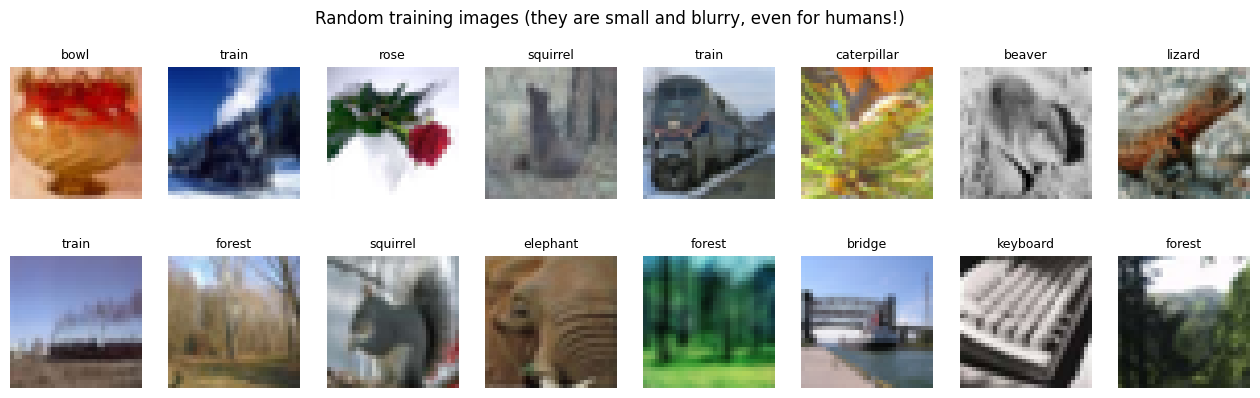

In [ ]:
# Take a look at some images
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, i in zip(axes.flat, np.random.RandomState(0).choice(len(x_train), 16, replace=False)):
    ax.imshow(x_train[i])
    ax.set_title(CLASS_NAMES[y_train[i]], fontsize=9)
    ax.axis("off")
plt.suptitle("Random training images (they are small and blurry, even for humans!)")
plt.show()

## Step 2: The model (you do not need to edit this)

This function builds a CNN from a dictionary of settings called `cfg`. Each block has two convolution layers, batch normalisation, max pooling and dropout. The number of filters doubles after every block.

Read it, get curious about it, but all the tuning in this challenge happens through the `cfg` dictionary.

In [ ]:
def build_model(cfg):
    reg = keras.regularizers.l2(cfg["l2"]) if cfg["l2"] > 0 else None

    inputs = keras.Input(shape=(32, 32, 3))
    x = layers.Rescaling(1.0 / 255)(inputs)          # turn pixel values 0-255 into 0-1

    # Data augmentation: random changes to training images (only active while training)
    if cfg["augment"]:
        x = layers.RandomFlip("horizontal")(x)
        x = layers.RandomTranslation(0.1, 0.1)(x)
        x = layers.RandomRotation(0.05)(x)

    filters = cfg["base_filters"]
    for _ in range(cfg["num_blocks"]):
        for _ in range(2):
            x = layers.Conv2D(filters, 3, padding="same", use_bias=False, kernel_regularizer=reg)(x)
            x = layers.BatchNormalization()(x)
            x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(cfg["dropout"])(x)
        filters *= 2

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(cfg["dense_units"], activation="relu", kernel_regularizer=reg)(x)
    x = layers.Dropout(cfg["dropout"])(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs)


def get_optimizer(cfg):
    name, lr = cfg["optimizer"].lower(), cfg["learning_rate"]
    if name == "adam":
        return keras.optimizers.Adam(learning_rate=lr)
    if name == "adamw":
        return keras.optimizers.AdamW(learning_rate=lr, weight_decay=1e-4)
    if name == "sgd":
        return keras.optimizers.SGD(learning_rate=lr, momentum=0.9, nesterov=True)
    if name == "rmsprop":
        return keras.optimizers.RMSprop(learning_rate=lr)
    raise ValueError("optimizer must be one of: adam, adamw, sgd, rmsprop")

## Step 3: The experiment runner (you do not need to edit this)

`run_experiment(cfg, notes)` does everything for one experiment:
- builds and trains the model with your settings,
- stops early if the model stops improving (saves time),
- plots the learning curves,
- **adds a row to your results table** and saves it to `experiment_log.csv`,
- keeps a copy of the best model so far in `best_model.keras`.

The `notes` text is for you: write what you changed and why.

In [ ]:
LOG_FILE, BEST_MODEL_FILE = "experiment_log.csv", "best_model.keras"

# Reload earlier results if the file exists (handy if you rerun this cell)
if os.path.exists(LOG_FILE):
    experiment_log = pd.read_csv(LOG_FILE).to_dict("records")
else:
    experiment_log = []
best_val_so_far = max([r["val_acc"] for r in experiment_log], default=0.0) if os.path.exists(BEST_MODEL_FILE) else 0.0


def make_ds(x, y, batch_size, training):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        ds = ds.shuffle(len(x), seed=SEED)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)


def plot_history(history, title):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
    a1.plot(history.history["loss"], label="train"); a1.plot(history.history["val_loss"], label="validation")
    a1.set_title("Loss (lower is better)"); a1.set_xlabel("epoch"); a1.legend()
    a2.plot(history.history["accuracy"], label="train"); a2.plot(history.history["val_accuracy"], label="validation")
    a2.set_title("Accuracy (higher is better)"); a2.set_xlabel("epoch"); a2.legend()
    fig.suptitle(title); plt.show()


def run_experiment(cfg, notes=""):
    global best_val_so_far
    keras.backend.clear_session()
    tf.random.set_seed(SEED)

    train_ds = make_ds(x_train, y_train, cfg["batch_size"], training=True)
    val_ds = make_ds(x_val, y_val, cfg["batch_size"], training=False)

    model = build_model(cfg)
    model.compile(optimizer=get_optimizer(cfg), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    callbacks = [keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=cfg["patience"],
                                               restore_best_weights=True)]
    if cfg["use_lr_schedule"]:
        callbacks.append(keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6))

    start = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=cfg["epochs"], callbacks=callbacks, verbose=2)
    minutes = (time.time() - start) / 60

    h = history.history
    best = int(np.argmax(h["val_accuracy"]))          # the epoch with the best validation accuracy
    row = {"run": len(experiment_log) + 1, "notes": notes}
    row.update(cfg)
    row.update({
        "train_acc": round(h["accuracy"][best], 4),
        "val_acc": round(h["val_accuracy"][best], 4),
        "val_loss": round(h["val_loss"][best], 4),
        "gap": round(h["accuracy"][best] - h["val_accuracy"][best], 4),   # big gap = overfitting
        "best_epoch": best + 1,
        "epochs_run": len(h["loss"]),
        "minutes": round(minutes, 1),
        "params": model.count_params(),
    })
    experiment_log.append(row)
    pd.DataFrame(experiment_log).to_csv(LOG_FILE, index=False)

    if row["val_acc"] > best_val_so_far:
        best_val_so_far = row["val_acc"]
        model.save(BEST_MODEL_FILE)
        print("New best model saved!")

    plot_history(history, f"Run {row['run']}: {notes}")
    print(f"Run {row['run']} | val_acc = {row['val_acc']:.4f} | train_acc = {row['train_acc']:.4f} | "
          f"gap = {row['gap']:.4f} | {row['minutes']} min")
    return model

## Step 4: Baseline run

This is the starting point. It uses reasonable but un-tuned settings. Run it and note the validation accuracy. **This is the number you are trying to beat.**

Here is what each setting means:

| Setting | Meaning |
|---------|---------|
| `learning_rate` | How big a step the model takes when learning. Too high: unstable. Too low: very slow. |
| `batch_size` | How many images are used for each update. |
| `epochs` | Maximum passes over the training data (early stopping may end sooner). |
| `optimizer` | The learning algorithm: `adam`, `adamw`, `sgd`, `rmsprop`. |
| `dropout` | Fraction of neurons randomly switched off while training (fights overfitting). |
| `l2` | Weight penalty (fights overfitting). `0` means off. |
| `base_filters` | Width of the first conv layer. It doubles each block. Bigger = more capacity. |
| `num_blocks` | Depth of the network (1 to 4). |
| `dense_units` | Size of the fully connected layer before the output. |
| `augment` | `True` randomly flips, shifts and rotates training images. |
| `use_lr_schedule` | `True` halves the learning rate when progress stalls. |
| `patience` | Epochs to wait without improvement before stopping early. |

Epoch 1/30
53/53 - 33s - 621ms/step - accuracy: 0.1932 - loss: 2.5646 - val_accuracy: 0.0836 - val_loss: 2.9808
Epoch 2/30
53/53 - 1s - 12ms/step - accuracy: 0.2695 - loss: 2.2381 - val_accuracy: 0.1003 - val_loss: 3.3139
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.3256 - loss: 2.1116 - val_accuracy: 0.1104 - val_loss: 3.9288
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.3592 - loss: 1.9724 - val_accuracy: 0.0953 - val_loss: 3.8235
Epoch 5/30
53/53 - 1s - 10ms/step - accuracy: 0.3869 - loss: 1.9091 - val_accuracy: 0.0953 - val_loss: 3.9295
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.4238 - loss: 1.7850 - val_accuracy: 0.1472 - val_loss: 4.0958
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.4444 - loss: 1.7238 - val_accuracy: 0.1555 - val_loss: 3.3096
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.4686 - loss: 1.6271 - val_accuracy: 0.1789 - val_loss: 3.0036
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.4845 - loss: 1.5779 - val_accuracy: 0.2391 - val_loss: 2.7703
Epoch 10

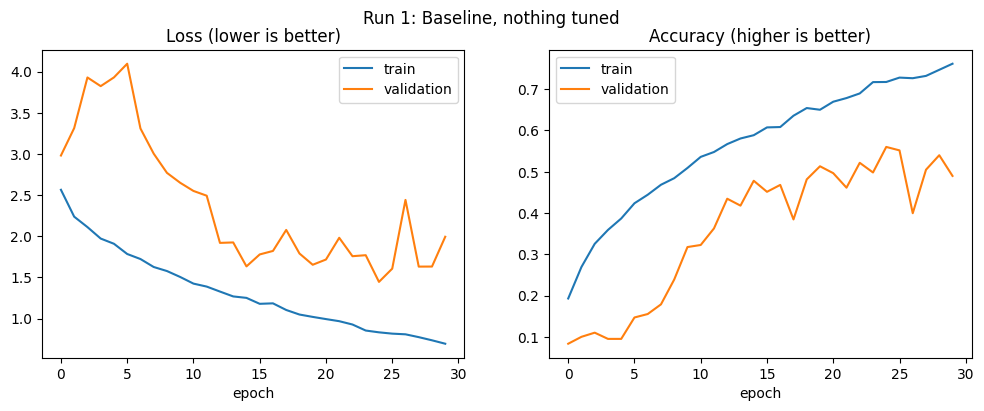

Run 1 | val_acc = 0.5602 | train_acc = 0.7175 | gap = 0.1573 | 0.8 min


In [ ]:
baseline_cfg = {
    "learning_rate": 0.001,
    "batch_size": 64,
    "epochs": 30,
    "optimizer": "adam",
    "dropout": 0.25,
    "l2": 0.0,
    "base_filters": 32,
    "num_blocks": 3,
    "dense_units": 256,
    "augment": False,
    "use_lr_schedule": False,
    "patience": 6,
}

model = run_experiment(baseline_cfg, notes="Baseline, nothing tuned")

## Step 5: YOUR TURN, run experiments

### The golden rule: change ONE thing at a time
If you change three settings and the score goes up, you will not know which change helped.

### The loop
1. Look at the learning curves and the `gap` column from your last run.
2. Form a guess ("The model is overfitting, so more dropout might help").
3. Copy your best config, change **one** value, and write a clear `notes` message.
4. Run it. Check the table in Step 6. Repeat.

### Reading the curves
| What you see | What it probably means | Things to try |
|--------------|------------------------|---------------|
| Train and validation accuracy both low | Underfitting | Bigger model (`base_filters`, `num_blocks`), higher learning rate, train longer |
| Train accuracy high, validation much lower (large `gap`) | Overfitting | `augment=True`, more `dropout`, `l2` > 0, smaller model |
| Validation loss jumps around wildly | Learning rate too high | Lower `learning_rate`, `use_lr_schedule=True` |
| Training is very slow to improve | Learning rate too low | Raise `learning_rate` |
| Stops early at a poor score | `patience` too small | Increase `patience` and `epochs` |

### Ideas for a good search order
1. `augment` (usually a big win on CIFAR-100)
2. `learning_rate` (try 0.01, 0.003, 0.0003)
3. `dropout` (0.1, 0.3, 0.4, 0.5)
4. `use_lr_schedule` and a larger `epochs`
5. Model size: `base_filters` (64) and `num_blocks`
6. `batch_size` (32, 128) and `optimizer`
7. Finally, combine the good ideas and fine-tune around them

Below is a template. Edit the lines marked with `# CHANGE`.

In [ ]:
# Experiment 2: copy of the baseline with ONE change
cfg = dict(baseline_cfg)            # start from a known config
cfg["augment"] = True               # CHANGE: the one thing you are testing

model = run_experiment(cfg, notes="Turned on data augmentation")

In [ ]:
# Experiment 3: build on whatever worked best so far
cfg = dict(baseline_cfg)
cfg["augment"] = True               # keep what helped
cfg["learning_rate"] = 0.003        # CHANGE: the new thing you are testing

model = run_experiment(cfg, notes="Augment on, learning rate 0.003")

In [ ]:
# Experiment 4: copy this cell as many times as you need (use the + Code button)
cfg = dict(baseline_cfg)
cfg["augment"] = True
# cfg["..."] = ...                  # CHANGE

model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
53/53 - 10s - 186ms/step - accuracy: 0.1834 - loss: 2.5601 - val_accuracy: 0.0502 - val_loss: 3.0734
Epoch 2/30
53/53 - 1s - 19ms/step - accuracy: 0.2574 - loss: 2.2727 - val_accuracy: 0.0468 - val_loss: 3.4647
Epoch 3/30
53/53 - 1s - 24ms/step - accuracy: 0.2852 - loss: 2.1913 - val_accuracy: 0.0468 - val_loss: 3.6020
Epoch 4/30
53/53 - 1s - 19ms/step - accuracy: 0.2990 - loss: 2.1248 - val_accuracy: 0.0602 - val_loss: 3.7710
Epoch 5/30
53/53 - 1s - 19ms/step - accuracy: 0.3197 - loss: 2.0783 - val_accuracy: 0.0803 - val_loss: 3.5992
Epoch 6/30
53/53 - 1s - 19ms/step - accuracy: 0.3424 - loss: 2.0023 - val_accuracy: 0.1304 - val_loss: 3.6668
Epoch 7/30
53/53 - 1s - 19ms/step - accuracy: 0.3671 - loss: 1.9642 - val_accuracy: 0.2023 - val_loss: 2.8254
Epoch 8/30
53/53 - 1s - 19ms/step - accuracy: 0.3828 - loss: 1.8866 - val_accuracy: 0.2023 - val_loss: 2.7584
Epoch 9/30
53/53 - 1s - 19ms/step - accuracy: 0.4096 - loss: 1.8294 - val_accuracy: 0.2542 - val_loss: 2.5163
Epoch 10

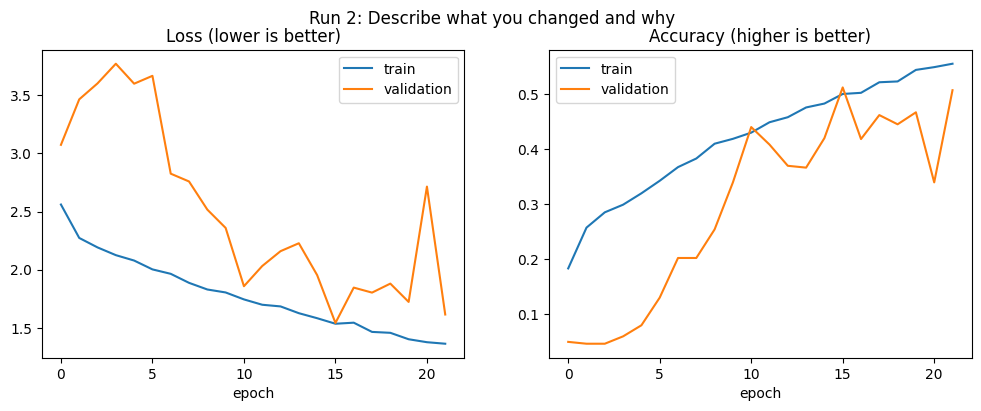

Run 2 | val_acc = 0.5117 | train_acc = 0.4999 | gap = -0.0119 | 0.5 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = True
# cfg["..."] = ...                  # CHANGE

model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
53/53 - 18s - 335ms/step - accuracy: 0.1769 - loss: 2.5799 - val_accuracy: 0.1355 - val_loss: 2.7821
Epoch 2/30
53/53 - 1s - 11ms/step - accuracy: 0.2309 - loss: 2.3254 - val_accuracy: 0.0970 - val_loss: 3.6910
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.2642 - loss: 2.2453 - val_accuracy: 0.0853 - val_loss: 3.7903
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.2881 - loss: 2.1409 - val_accuracy: 0.0853 - val_loss: 4.5152
Epoch 5/30
53/53 - 1s - 10ms/step - accuracy: 0.3105 - loss: 2.0888 - val_accuracy: 0.0920 - val_loss: 5.4215
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.3427 - loss: 2.0079 - val_accuracy: 0.1288 - val_loss: 6.2604
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.3713 - loss: 1.9197 - val_accuracy: 0.2592 - val_loss: 2.4745
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.3834 - loss: 1.8510 - val_accuracy: 0.2425 - val_loss: 2.5916
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.4252 - loss: 1.7824 - val_accuracy: 0.2659 - val_loss: 2.7863
Epoch 10

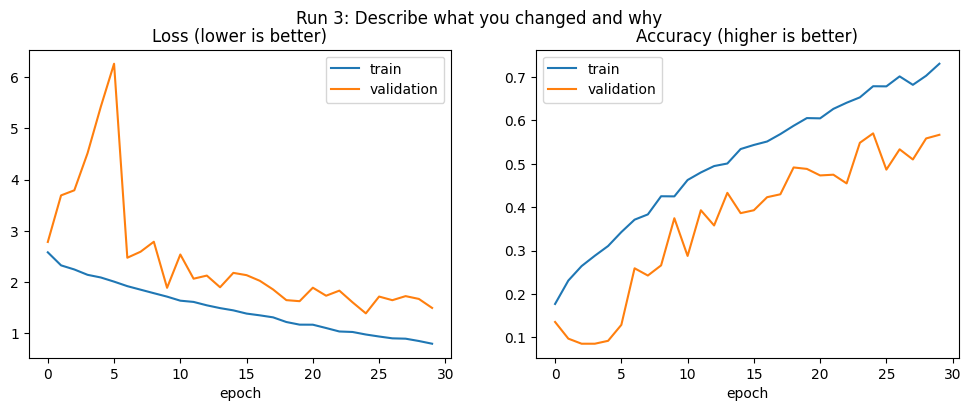

Run 3 | val_acc = 0.5702 | train_acc = 0.6789 | gap = 0.1086 | 0.6 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.002
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
53/53 - 17s - 327ms/step - accuracy: 0.1846 - loss: 2.5625 - val_accuracy: 0.0886 - val_loss: 2.8247
Epoch 2/30
53/53 - 1s - 11ms/step - accuracy: 0.2409 - loss: 2.3113 - val_accuracy: 0.1037 - val_loss: 3.1147
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.2861 - loss: 2.1994 - val_accuracy: 0.1054 - val_loss: 3.7055
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.2940 - loss: 2.1152 - val_accuracy: 0.1555 - val_loss: 3.6154
Epoch 5/30
53/53 - 1s - 10ms/step - accuracy: 0.3232 - loss: 2.0707 - val_accuracy: 0.1405 - val_loss: 3.8082
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.3568 - loss: 1.9586 - val_accuracy: 0.1605 - val_loss: 3.4673
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.3698 - loss: 1.9126 - val_accuracy: 0.2007 - val_loss: 2.9505
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.4031 - loss: 1.8360 - val_accuracy: 0.2441 - val_loss: 3.0636
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.4232 - loss: 1.7571 - val_accuracy: 0.3478 - val_loss: 2.1587
Epoch 10

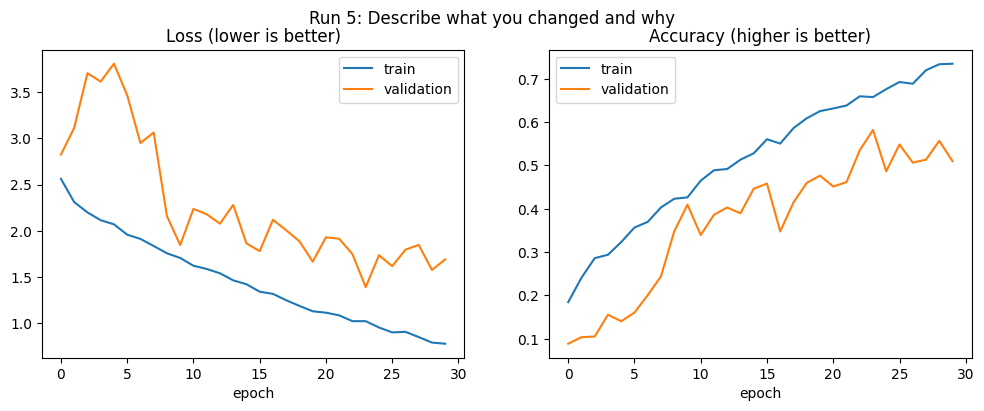

Run 5 | val_acc = 0.5819 | train_acc = 0.6579 | gap = 0.0760 | 0.6 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.0024
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
53/53 - 18s - 342ms/step - accuracy: 0.1820 - loss: 2.5788 - val_accuracy: 0.0886 - val_loss: 3.1459
Epoch 2/30
53/53 - 1s - 12ms/step - accuracy: 0.2321 - loss: 2.3310 - val_accuracy: 0.1137 - val_loss: 3.3378
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.2639 - loss: 2.2396 - val_accuracy: 0.1321 - val_loss: 3.0982
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.2843 - loss: 2.1659 - val_accuracy: 0.1037 - val_loss: 3.6399
Epoch 5/30
53/53 - 1s - 10ms/step - accuracy: 0.3049 - loss: 2.1086 - val_accuracy: 0.1789 - val_loss: 2.6029
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.3365 - loss: 2.0281 - val_accuracy: 0.1187 - val_loss: 4.3240
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.3645 - loss: 1.9512 - val_accuracy: 0.3127 - val_loss: 2.3576
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.3674 - loss: 1.9073 - val_accuracy: 0.3010 - val_loss: 2.2552
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.3872 - loss: 1.8556 - val_accuracy: 0.2709 - val_loss: 2.7790
Epoch 10

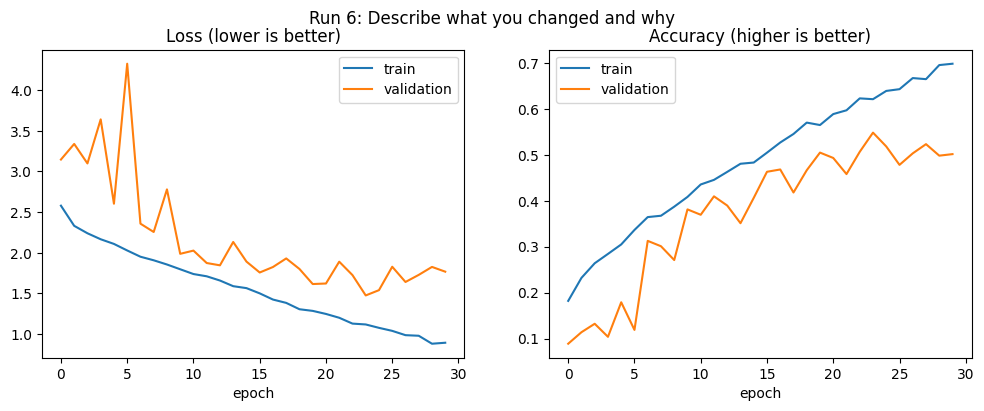

Run 6 | val_acc = 0.5485 | train_acc = 0.6214 | gap = 0.0729 | 0.6 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.0026
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
53/53 - 18s - 335ms/step - accuracy: 0.1693 - loss: 2.6087 - val_accuracy: 0.1756 - val_loss: 2.6257
Epoch 2/30
53/53 - 1s - 12ms/step - accuracy: 0.2241 - loss: 2.3460 - val_accuracy: 0.1923 - val_loss: 2.4965
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.2507 - loss: 2.2910 - val_accuracy: 0.1171 - val_loss: 3.0132
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.2660 - loss: 2.2170 - val_accuracy: 0.1137 - val_loss: 3.4248
Epoch 5/30
53/53 - 1s - 10ms/step - accuracy: 0.2852 - loss: 2.1675 - val_accuracy: 0.2057 - val_loss: 2.5021
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.3037 - loss: 2.0974 - val_accuracy: 0.2124 - val_loss: 2.5894
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.3232 - loss: 2.0523 - val_accuracy: 0.2592 - val_loss: 2.4543
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.3329 - loss: 2.0013 - val_accuracy: 0.2341 - val_loss: 2.4795
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.3556 - loss: 1.9602 - val_accuracy: 0.3194 - val_loss: 2.0863
Epoch 10

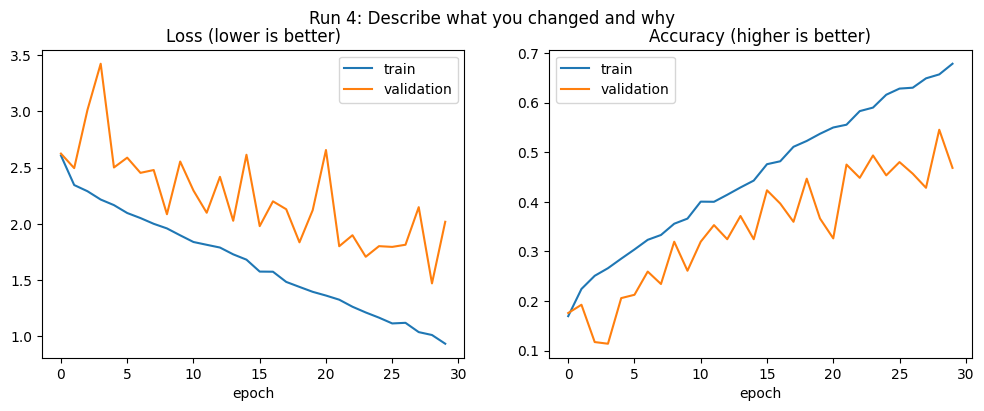

Run 4 | val_acc = 0.5452 | train_acc = 0.6567 | gap = 0.1116 | 0.6 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.003
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
106/106 - 29s - 270ms/step - accuracy: 0.1879 - loss: 2.5385 - val_accuracy: 0.0552 - val_loss: 3.6891
Epoch 2/30
106/106 - 1s - 7ms/step - accuracy: 0.2271 - loss: 2.3592 - val_accuracy: 0.2057 - val_loss: 2.6484
Epoch 3/30
106/106 - 1s - 6ms/step - accuracy: 0.2687 - loss: 2.2470 - val_accuracy: 0.1839 - val_loss: 2.8073
Epoch 4/30
106/106 - 1s - 6ms/step - accuracy: 0.2757 - loss: 2.1990 - val_accuracy: 0.2910 - val_loss: 2.3607
Epoch 5/30
106/106 - 1s - 9ms/step - accuracy: 0.2984 - loss: 2.1458 - val_accuracy: 0.2375 - val_loss: 2.9669
Epoch 6/30
106/106 - 1s - 9ms/step - accuracy: 0.3229 - loss: 2.0980 - val_accuracy: 0.3077 - val_loss: 2.8517
Epoch 7/30
106/106 - 1s - 12ms/step - accuracy: 0.3382 - loss: 2.0223 - val_accuracy: 0.1739 - val_loss: 4.2133
Epoch 8/30
106/106 - 1s - 6ms/step - accuracy: 0.3495 - loss: 1.9553 - val_accuracy: 0.2826 - val_loss: 2.5389
Epoch 9/30
106/106 - 1s - 6ms/step - accuracy: 0.3701 - loss: 1.9350 - val_accuracy: 0.3311 - val_loss: 2.11

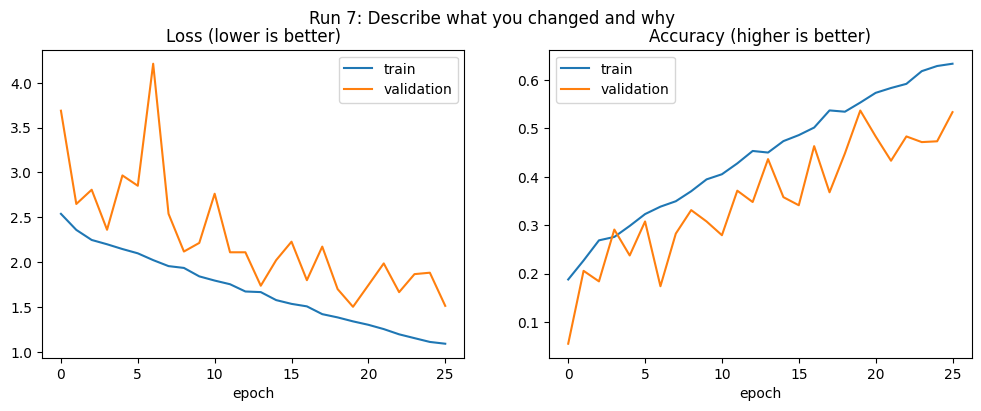

Run 7 | val_acc = 0.5368 | train_acc = 0.5532 | gap = 0.0164 | 0.8 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.0024
cfg["batch_size"]=32
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
4/4 - 35s - 9s/step - accuracy: 0.0988 - loss: 3.0975 - val_accuracy: 0.0803 - val_loss: 2.9713
Epoch 2/30
4/4 - 0s - 104ms/step - accuracy: 0.1713 - loss: 2.6405 - val_accuracy: 0.0903 - val_loss: 2.9224
Epoch 3/30
4/4 - 0s - 100ms/step - accuracy: 0.1728 - loss: 2.5565 - val_accuracy: 0.0652 - val_loss: 2.9314
Epoch 4/30
4/4 - 0s - 100ms/step - accuracy: 0.1861 - loss: 2.4920 - val_accuracy: 0.0619 - val_loss: 2.9262
Epoch 5/30
4/4 - 0s - 103ms/step - accuracy: 0.2100 - loss: 2.4454 - val_accuracy: 0.1037 - val_loss: 2.9138
Epoch 6/30
4/4 - 0s - 103ms/step - accuracy: 0.2212 - loss: 2.4099 - val_accuracy: 0.1405 - val_loss: 2.7909
Epoch 7/30
4/4 - 0s - 101ms/step - accuracy: 0.2123 - loss: 2.4125 - val_accuracy: 0.1806 - val_loss: 2.6914
Epoch 8/30
4/4 - 0s - 100ms/step - accuracy: 0.2215 - loss: 2.4122 - val_accuracy: 0.1388 - val_loss: 2.6949
Epoch 9/30
4/4 - 0s - 98ms/step - accuracy: 0.1887 - loss: 2.4861 - val_accuracy: 0.1271 - val_loss: 2.6973
Epoch 10/30
4/4 - 0s -

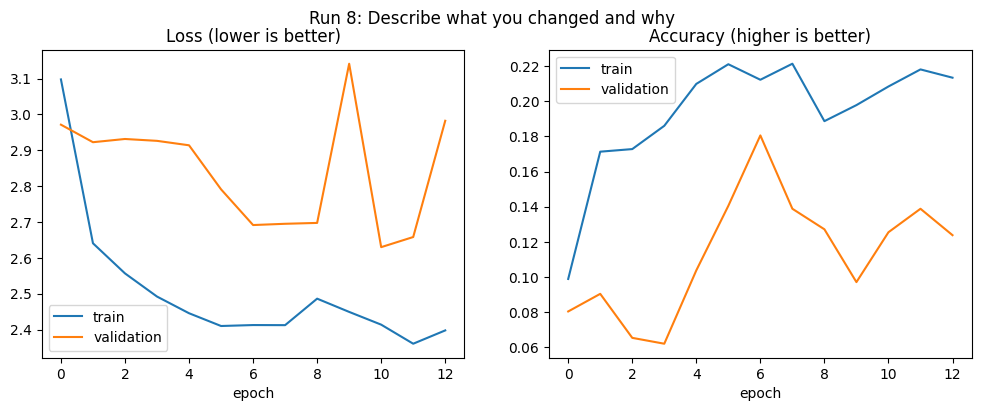

Run 8 | val_acc = 0.1806 | train_acc = 0.2123 | gap = 0.0317 | 0.7 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.0024
cfg["batch_size"]=1128
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
27/27 - 25s - 934ms/step - accuracy: 0.1793 - loss: 2.6113 - val_accuracy: 0.0953 - val_loss: 3.3544
Epoch 2/30
27/27 - 0s - 18ms/step - accuracy: 0.2515 - loss: 2.2866 - val_accuracy: 0.1087 - val_loss: 3.3826
Epoch 3/30
27/27 - 0s - 17ms/step - accuracy: 0.2861 - loss: 2.1820 - val_accuracy: 0.0903 - val_loss: 3.3111
Epoch 4/30
27/27 - 0s - 16ms/step - accuracy: 0.3029 - loss: 2.0982 - val_accuracy: 0.1037 - val_loss: 3.5726
Epoch 5/30
27/27 - 0s - 17ms/step - accuracy: 0.3359 - loss: 2.0381 - val_accuracy: 0.1237 - val_loss: 3.1726
Epoch 6/30
27/27 - 0s - 17ms/step - accuracy: 0.3613 - loss: 1.9651 - val_accuracy: 0.1137 - val_loss: 4.4383
Epoch 7/30
27/27 - 0s - 17ms/step - accuracy: 0.3902 - loss: 1.8757 - val_accuracy: 0.1288 - val_loss: 3.6346
Epoch 8/30
27/27 - 0s - 17ms/step - accuracy: 0.4105 - loss: 1.7872 - val_accuracy: 0.1488 - val_loss: 4.4246
Epoch 9/30
27/27 - 0s - 17ms/step - accuracy: 0.4412 - loss: 1.7467 - val_accuracy: 0.1371 - val_loss: 4.3185
Epoch 10

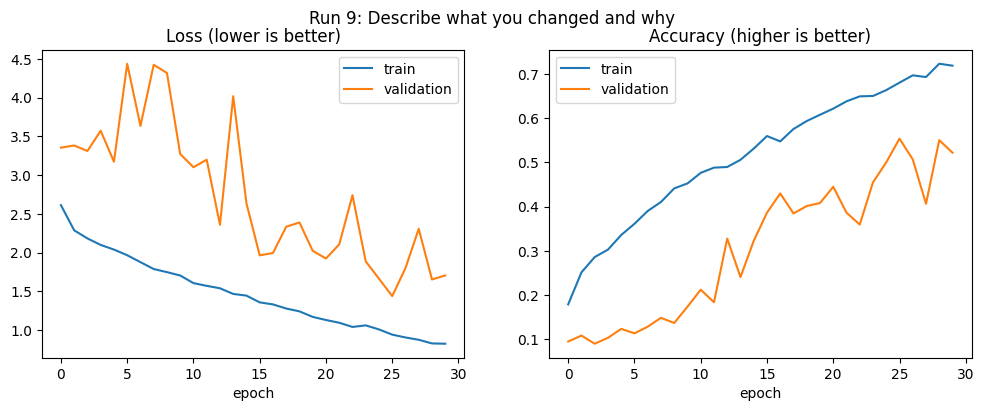

Run 9 | val_acc = 0.5535 | train_acc = 0.6800 | gap = 0.1265 | 0.6 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.0024
cfg["batch_size"]=128
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
53/53 - 18s - 341ms/step - accuracy: 0.1651 - loss: 2.6005 - val_accuracy: 0.1823 - val_loss: 2.9292
Epoch 2/30
53/53 - 1s - 11ms/step - accuracy: 0.2339 - loss: 2.3292 - val_accuracy: 0.1538 - val_loss: 2.9323
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.2468 - loss: 2.2709 - val_accuracy: 0.1689 - val_loss: 3.9179
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.2769 - loss: 2.1945 - val_accuracy: 0.1990 - val_loss: 3.4896
Epoch 5/30
53/53 - 1s - 10ms/step - accuracy: 0.2813 - loss: 2.1542 - val_accuracy: 0.1990 - val_loss: 2.7020
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.3032 - loss: 2.1212 - val_accuracy: 0.2408 - val_loss: 2.4935
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.3232 - loss: 2.0517 - val_accuracy: 0.2809 - val_loss: 2.1957
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.3589 - loss: 1.9669 - val_accuracy: 0.2358 - val_loss: 2.4668
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.3648 - loss: 1.9444 - val_accuracy: 0.2843 - val_loss: 2.2927
Epoch 10

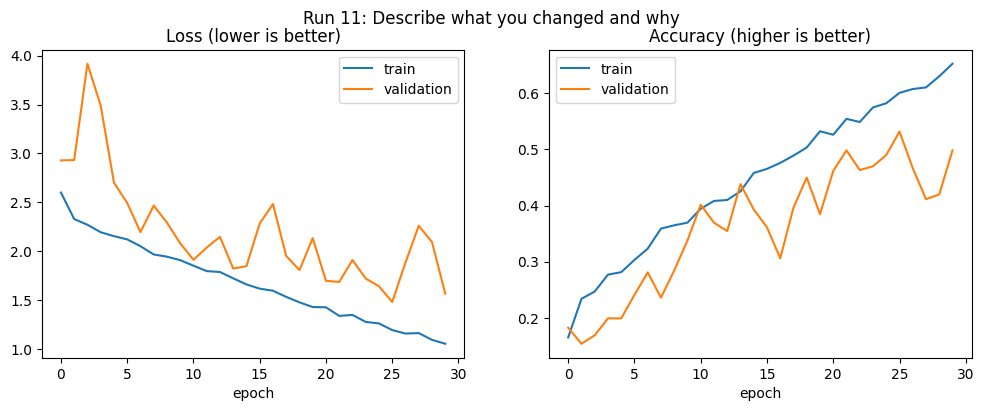

Run 11 | val_acc = 0.5318 | train_acc = 0.6007 | gap = 0.0689 | 0.6 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.004
cfg["batch_size"]=64

model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
53/53 - 18s - 341ms/step - accuracy: 0.1634 - loss: 2.6407 - val_accuracy: 0.1120 - val_loss: 3.3373
Epoch 2/30
53/53 - 1s - 11ms/step - accuracy: 0.2073 - loss: 2.3992 - val_accuracy: 0.1405 - val_loss: 3.3328
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.2462 - loss: 2.2840 - val_accuracy: 0.2090 - val_loss: 2.5989
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.2689 - loss: 2.2115 - val_accuracy: 0.2007 - val_loss: 2.7143
Epoch 5/30
53/53 - 1s - 10ms/step - accuracy: 0.2731 - loss: 2.1896 - val_accuracy: 0.1589 - val_loss: 3.2981
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.2875 - loss: 2.1597 - val_accuracy: 0.2776 - val_loss: 2.1724
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.3206 - loss: 2.0887 - val_accuracy: 0.2860 - val_loss: 2.2599
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.3208 - loss: 2.0501 - val_accuracy: 0.2759 - val_loss: 2.1932
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.3270 - loss: 2.0227 - val_accuracy: 0.1957 - val_loss: 3.5712
Epoch 10

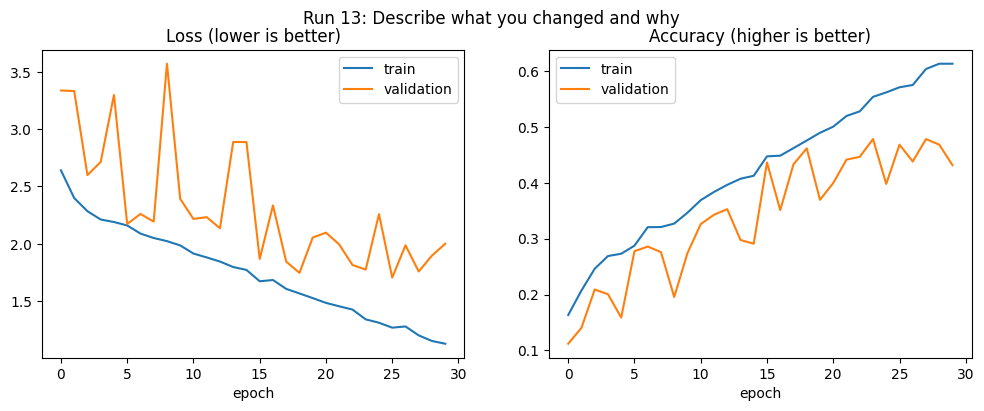

Run 13 | val_acc = 0.4783 | train_acc = 0.5538 | gap = 0.0756 | 0.6 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.004
cfg["batch_size"]=64
cfg["epoch"]=20
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
53/53 - 18s - 336ms/step - accuracy: 0.1755 - loss: 2.6031 - val_accuracy: 0.1288 - val_loss: 2.6627
Epoch 2/30
53/53 - 1s - 11ms/step - accuracy: 0.2247 - loss: 2.3519 - val_accuracy: 0.1171 - val_loss: 2.9927
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.2654 - loss: 2.2405 - val_accuracy: 0.1271 - val_loss: 3.1232
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.3005 - loss: 2.1496 - val_accuracy: 0.1321 - val_loss: 3.3831
Epoch 5/30
53/53 - 1s - 10ms/step - accuracy: 0.3135 - loss: 2.0920 - val_accuracy: 0.2258 - val_loss: 2.5129
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.3409 - loss: 2.0140 - val_accuracy: 0.1488 - val_loss: 3.8611
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.3677 - loss: 1.9317 - val_accuracy: 0.2542 - val_loss: 3.0491
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.3890 - loss: 1.8721 - val_accuracy: 0.2726 - val_loss: 2.3391
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.4158 - loss: 1.8216 - val_accuracy: 0.3261 - val_loss: 2.1824
Epoch 10

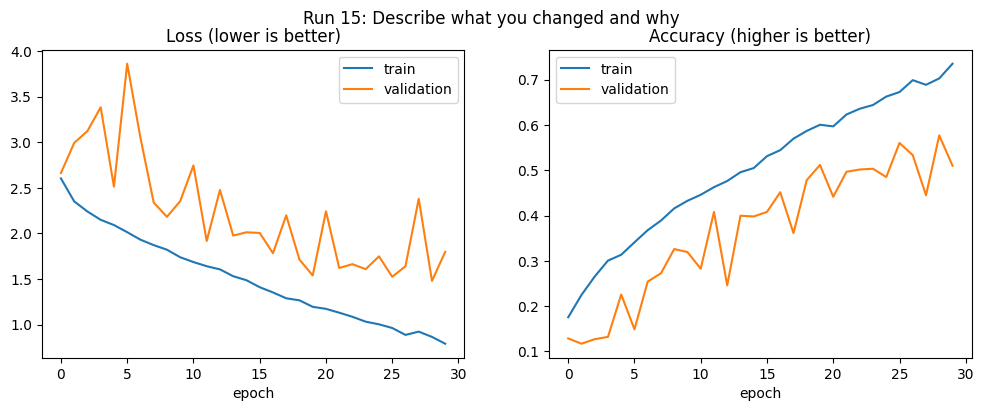

Run 15 | val_acc = 0.5769 | train_acc = 0.7027 | gap = 0.1258 | 0.6 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.0024
cfg["batch_size"]=64
cfg["epoch"]=20
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
53/53 - 18s - 339ms/step - accuracy: 0.1887 - loss: 2.5723 - val_accuracy: 0.1555 - val_loss: 2.7298
Epoch 2/30
53/53 - 1s - 11ms/step - accuracy: 0.2424 - loss: 2.3063 - val_accuracy: 0.0736 - val_loss: 3.3549
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.2678 - loss: 2.2324 - val_accuracy: 0.1338 - val_loss: 3.4470
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.2931 - loss: 2.1321 - val_accuracy: 0.1204 - val_loss: 4.9770
Epoch 5/30
53/53 - 1s - 10ms/step - accuracy: 0.3226 - loss: 2.0578 - val_accuracy: 0.1806 - val_loss: 3.7821
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.3607 - loss: 1.9681 - val_accuracy: 0.1254 - val_loss: 5.3695
Epoch 7/30
53/53 - 1s - 11ms/step - accuracy: 0.3666 - loss: 1.9157 - val_accuracy: 0.2358 - val_loss: 3.0176
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.3934 - loss: 1.8413 - val_accuracy: 0.2659 - val_loss: 2.8222
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.4199 - loss: 1.7597 - val_accuracy: 0.2893 - val_loss: 2.2681
Epoch 10

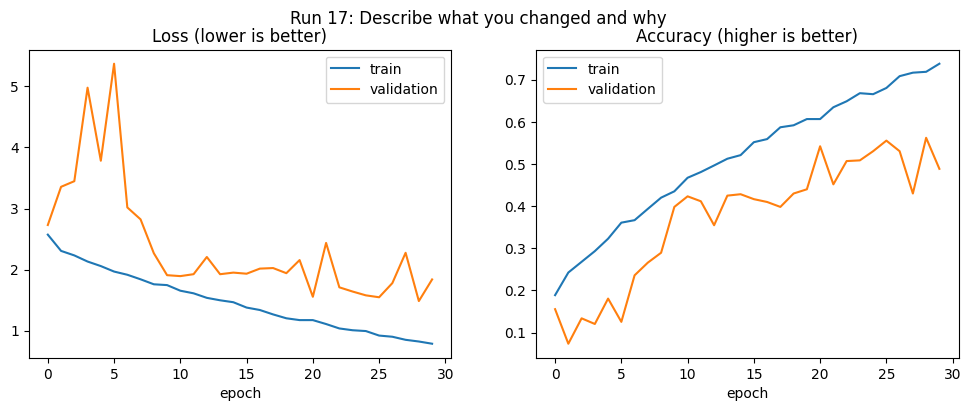

Run 17 | val_acc = 0.5619 | train_acc = 0.7184 | gap = 0.1565 | 0.6 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.0026
cfg["batch_size"]=64
cfg["epoch"]=20
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
53/53 - 18s - 334ms/step - accuracy: 0.1778 - loss: 2.5693 - val_accuracy: 0.1371 - val_loss: 2.7509
Epoch 2/30
53/53 - 1s - 11ms/step - accuracy: 0.2159 - loss: 2.3379 - val_accuracy: 0.1003 - val_loss: 3.3218
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.2648 - loss: 2.2560 - val_accuracy: 0.1237 - val_loss: 3.2417
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.2804 - loss: 2.1505 - val_accuracy: 0.1237 - val_loss: 3.2098
Epoch 5/30
53/53 - 1s - 10ms/step - accuracy: 0.2914 - loss: 2.1080 - val_accuracy: 0.1505 - val_loss: 2.9559
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.3247 - loss: 2.0347 - val_accuracy: 0.2023 - val_loss: 2.7888
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.3571 - loss: 1.9716 - val_accuracy: 0.2609 - val_loss: 2.4592
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.3666 - loss: 1.9113 - val_accuracy: 0.2174 - val_loss: 2.9527
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.3869 - loss: 1.8419 - val_accuracy: 0.2542 - val_loss: 2.5638
Epoch 10

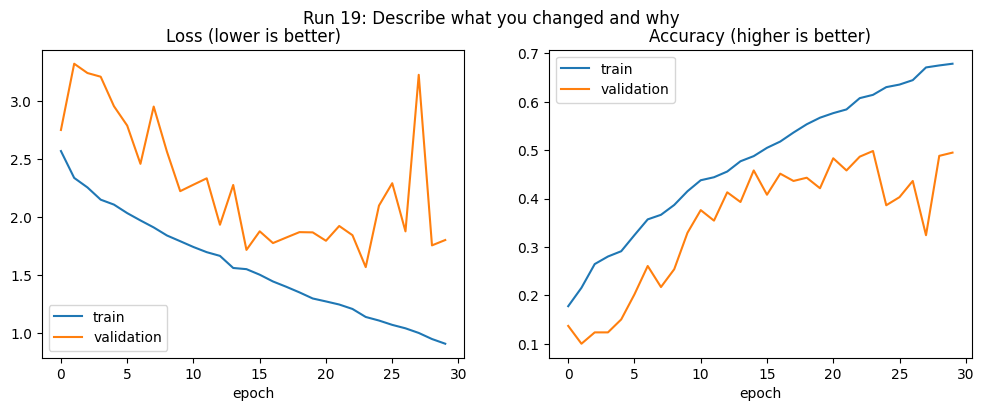

Run 19 | val_acc = 0.4983 | train_acc = 0.6143 | gap = 0.1159 | 0.6 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.0028
cfg["batch_size"]=64
cfg["epoch"]=23
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
53/53 - 18s - 337ms/step - accuracy: 0.1766 - loss: 2.5716 - val_accuracy: 0.1221 - val_loss: 2.8772
Epoch 2/30
53/53 - 1s - 11ms/step - accuracy: 0.2386 - loss: 2.3092 - val_accuracy: 0.1254 - val_loss: 3.3353
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.2622 - loss: 2.2376 - val_accuracy: 0.0853 - val_loss: 3.7841
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.2884 - loss: 2.1535 - val_accuracy: 0.1237 - val_loss: 3.5879
Epoch 5/30
53/53 - 1s - 10ms/step - accuracy: 0.2931 - loss: 2.1161 - val_accuracy: 0.1906 - val_loss: 2.7111
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.3223 - loss: 2.0560 - val_accuracy: 0.2007 - val_loss: 2.6457
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.3377 - loss: 1.9960 - val_accuracy: 0.2525 - val_loss: 2.2760
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.3627 - loss: 1.9264 - val_accuracy: 0.3194 - val_loss: 2.2561
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.3778 - loss: 1.8922 - val_accuracy: 0.2625 - val_loss: 2.5497
Epoch 10

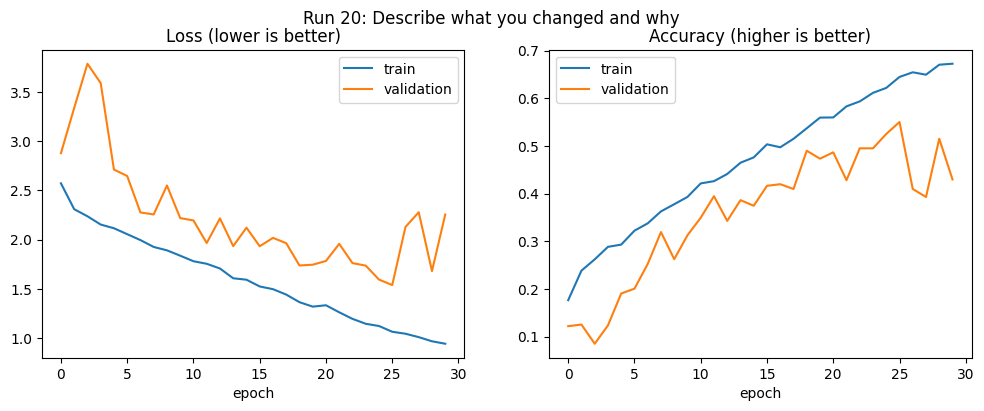

Run 20 | val_acc = 0.5502 | train_acc = 0.6446 | gap = 0.0945 | 0.6 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.0028
cfg["batch_size"]=64
cfg["epoch"]=40
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
53/53 - 18s - 338ms/step - accuracy: 0.1769 - loss: 2.6110 - val_accuracy: 0.1355 - val_loss: 2.8563
Epoch 2/30
53/53 - 1s - 12ms/step - accuracy: 0.2309 - loss: 2.3483 - val_accuracy: 0.1421 - val_loss: 2.8652
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.2545 - loss: 2.2810 - val_accuracy: 0.1455 - val_loss: 2.8330
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.2642 - loss: 2.2000 - val_accuracy: 0.1572 - val_loss: 2.9589
Epoch 5/30
53/53 - 1s - 10ms/step - accuracy: 0.2754 - loss: 2.1887 - val_accuracy: 0.1538 - val_loss: 3.0254
Epoch 6/30
53/53 - 1s - 11ms/step - accuracy: 0.3017 - loss: 2.1191 - val_accuracy: 0.2475 - val_loss: 2.7255
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.3279 - loss: 2.0359 - val_accuracy: 0.3194 - val_loss: 2.1716
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.3439 - loss: 1.9806 - val_accuracy: 0.2809 - val_loss: 2.2937
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.3559 - loss: 1.9415 - val_accuracy: 0.2776 - val_loss: 2.2345
Epoch 10

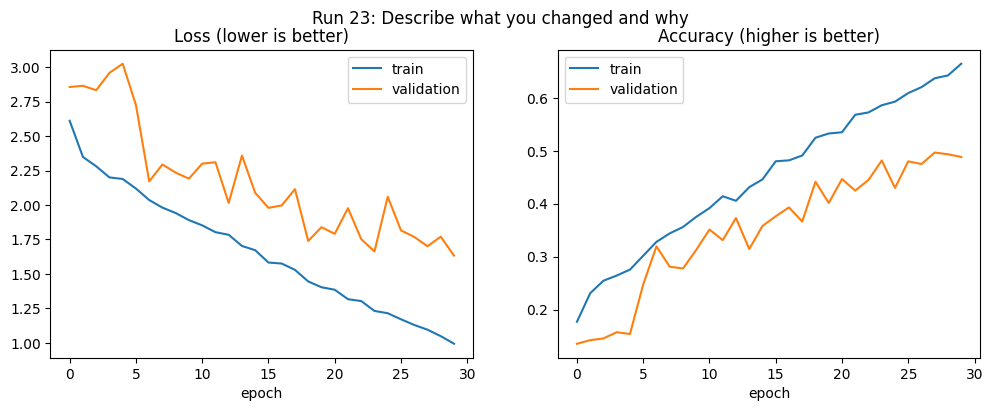

Run 23 | val_acc = 0.4967 | train_acc = 0.6370 | gap = 0.1403 | 0.6 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.003
cfg["batch_size"]=64
cfg["epoch"]=45
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
53/53 - 18s - 341ms/step - accuracy: 0.1416 - loss: 2.7379 - val_accuracy: 0.1237 - val_loss: 2.6698
Epoch 2/30
53/53 - 1s - 11ms/step - accuracy: 0.2014 - loss: 2.4345 - val_accuracy: 0.1789 - val_loss: 2.7668
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.2194 - loss: 2.3753 - val_accuracy: 0.1839 - val_loss: 2.6707
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.2445 - loss: 2.2904 - val_accuracy: 0.1656 - val_loss: 2.6501
Epoch 5/30
53/53 - 1s - 10ms/step - accuracy: 0.2521 - loss: 2.2574 - val_accuracy: 0.2007 - val_loss: 2.5965
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.2728 - loss: 2.2243 - val_accuracy: 0.2291 - val_loss: 2.4194
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.2804 - loss: 2.1791 - val_accuracy: 0.2926 - val_loss: 2.2029
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.2961 - loss: 2.1289 - val_accuracy: 0.2676 - val_loss: 2.2123
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.2976 - loss: 2.1003 - val_accuracy: 0.2893 - val_loss: 2.1969
Epoch 10

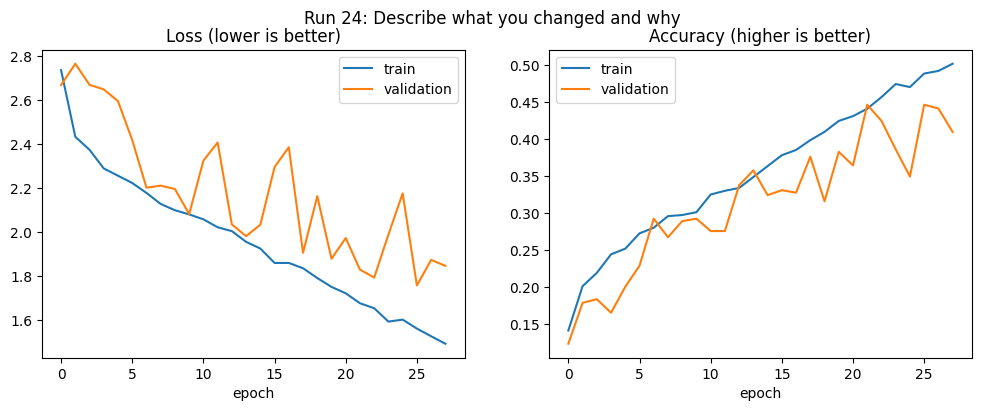

Run 24 | val_acc = 0.4465 | train_acc = 0.4412 | gap = -0.0053 | 0.5 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.003
cfg["batch_size"]=64
cfg["epoch"]=45
cfg["dropout"]=0.4
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
53/53 - 18s - 338ms/step - accuracy: 0.1988 - loss: 2.5033 - val_accuracy: 0.0819 - val_loss: 3.0872
Epoch 2/30
53/53 - 1s - 11ms/step - accuracy: 0.2572 - loss: 2.2613 - val_accuracy: 0.0803 - val_loss: 3.8120
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.2878 - loss: 2.1855 - val_accuracy: 0.1104 - val_loss: 4.0040
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.3067 - loss: 2.0847 - val_accuracy: 0.1120 - val_loss: 4.1333
Epoch 5/30
53/53 - 1s - 10ms/step - accuracy: 0.3424 - loss: 2.0020 - val_accuracy: 0.1455 - val_loss: 3.8077
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.3757 - loss: 1.9173 - val_accuracy: 0.1505 - val_loss: 4.2727
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.4017 - loss: 1.8158 - val_accuracy: 0.3194 - val_loss: 2.2227
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.4276 - loss: 1.7316 - val_accuracy: 0.2860 - val_loss: 2.2698
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.4527 - loss: 1.6474 - val_accuracy: 0.4030 - val_loss: 1.9358
Epoch 10

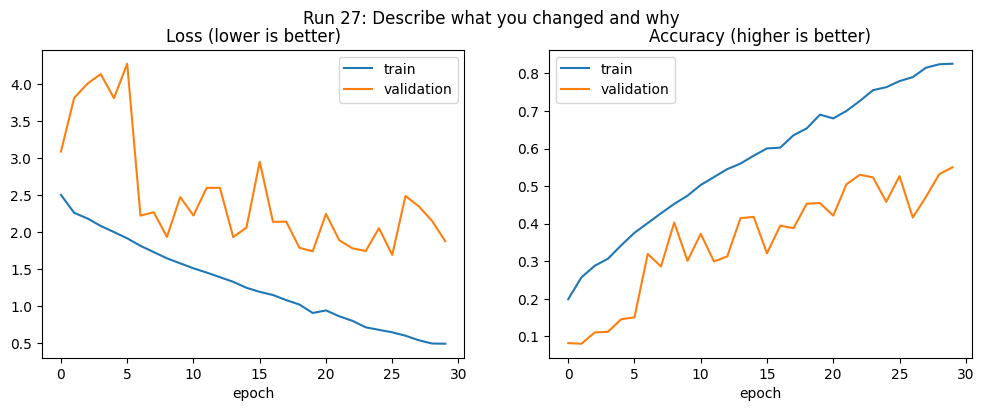

Run 27 | val_acc = 0.5502 | train_acc = 0.8260 | gap = 0.2758 | 0.6 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.003
cfg["batch_size"]=64
cfg["epoch"]=45
cfg["dropout"]=0.11
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
53/53 - 18s - 342ms/step - accuracy: 0.1849 - loss: 2.5578 - val_accuracy: 0.1656 - val_loss: 2.5697
Epoch 2/30
53/53 - 1s - 11ms/step - accuracy: 0.2315 - loss: 2.3130 - val_accuracy: 0.1020 - val_loss: 3.1353
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.2713 - loss: 2.2167 - val_accuracy: 0.1087 - val_loss: 3.5031
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.2872 - loss: 2.1253 - val_accuracy: 0.1120 - val_loss: 3.3258
Epoch 5/30
53/53 - 1s - 11ms/step - accuracy: 0.3138 - loss: 2.0602 - val_accuracy: 0.2241 - val_loss: 2.4276
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.3462 - loss: 1.9828 - val_accuracy: 0.1890 - val_loss: 3.0929
Epoch 7/30
53/53 - 1s - 11ms/step - accuracy: 0.3798 - loss: 1.8978 - val_accuracy: 0.2709 - val_loss: 2.7767
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.4046 - loss: 1.8305 - val_accuracy: 0.2809 - val_loss: 2.4117
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.4152 - loss: 1.7722 - val_accuracy: 0.3127 - val_loss: 2.3831
Epoch 10

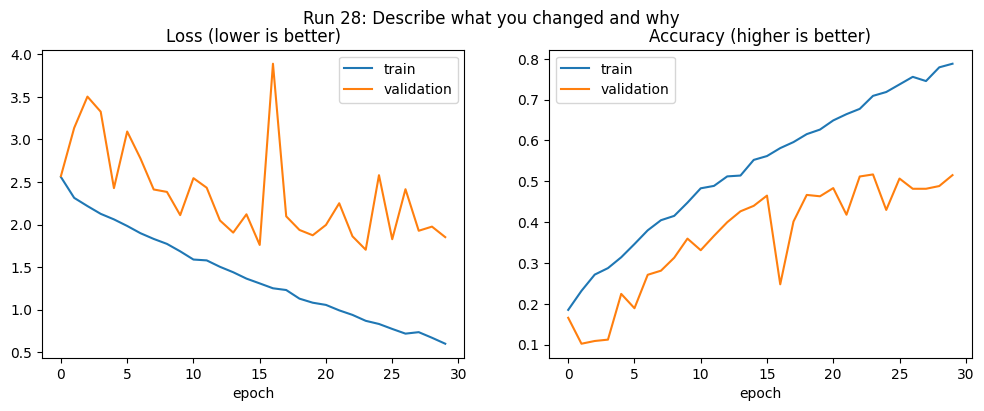

Run 28 | val_acc = 0.5167 | train_acc = 0.7092 | gap = 0.1925 | 0.6 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.0027
cfg["batch_size"]=64
cfg["epoch"]=40
cfg["dropout"]=0.14
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
53/53 - 18s - 339ms/step - accuracy: 0.1763 - loss: 2.5781 - val_accuracy: 0.1823 - val_loss: 2.6490
Epoch 2/30
53/53 - 1s - 11ms/step - accuracy: 0.2350 - loss: 2.3143 - val_accuracy: 0.1438 - val_loss: 2.9736
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.2630 - loss: 2.2353 - val_accuracy: 0.1087 - val_loss: 3.8694
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.2760 - loss: 2.1776 - val_accuracy: 0.1054 - val_loss: 3.8495
Epoch 5/30
53/53 - 1s - 12ms/step - accuracy: 0.2828 - loss: 2.1270 - val_accuracy: 0.1070 - val_loss: 3.3932
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.3117 - loss: 2.0682 - val_accuracy: 0.2057 - val_loss: 2.9014
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.3427 - loss: 2.0021 - val_accuracy: 0.2542 - val_loss: 2.7175
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.3595 - loss: 1.9364 - val_accuracy: 0.2408 - val_loss: 2.5089
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.3813 - loss: 1.8793 - val_accuracy: 0.2458 - val_loss: 2.7904
Epoch 10

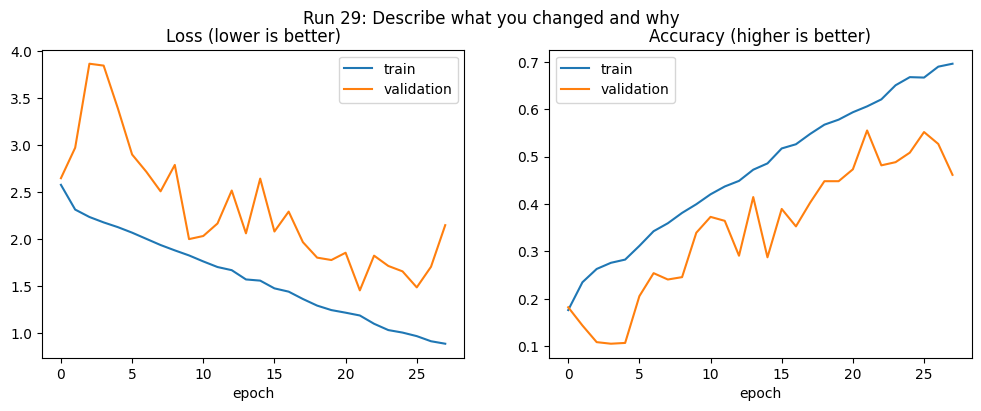

Run 29 | val_acc = 0.5552 | train_acc = 0.6060 | gap = 0.0508 | 0.5 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.003
cfg["batch_size"]=64
cfg["epoch"]=45
cfg["dropout"]=0.18
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
53/53 - 18s - 337ms/step - accuracy: 0.1587 - loss: 2.6299 - val_accuracy: 0.1171 - val_loss: 2.6270
Epoch 2/30
53/53 - 1s - 11ms/step - accuracy: 0.2197 - loss: 2.3549 - val_accuracy: 0.1706 - val_loss: 2.7367
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.2598 - loss: 2.2736 - val_accuracy: 0.1388 - val_loss: 3.2429
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.2754 - loss: 2.1816 - val_accuracy: 0.1388 - val_loss: 3.2533
Epoch 5/30
53/53 - 1s - 10ms/step - accuracy: 0.2925 - loss: 2.1354 - val_accuracy: 0.1522 - val_loss: 3.1189
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.3276 - loss: 2.0701 - val_accuracy: 0.1338 - val_loss: 4.1800
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.3506 - loss: 1.9981 - val_accuracy: 0.2525 - val_loss: 2.7679
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.3630 - loss: 1.9171 - val_accuracy: 0.2876 - val_loss: 2.2569
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.3784 - loss: 1.8839 - val_accuracy: 0.3010 - val_loss: 2.3095
Epoch 10

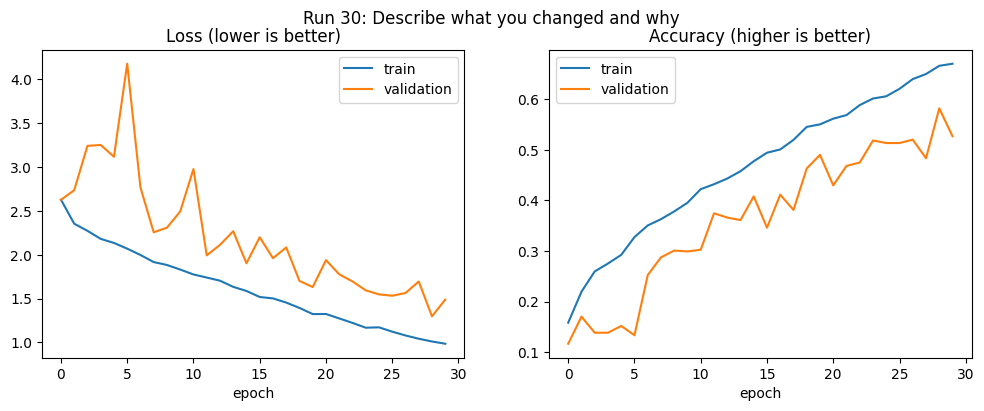

Run 30 | val_acc = 0.5819 | train_acc = 0.6659 | gap = 0.0839 | 0.6 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.0022
cfg["batch_size"]=64
cfg["epoch"]=45
cfg["dropout"]=0.3
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
53/53 - 5s - 95ms/step - accuracy: 0.1699 - loss: 2.6350 - val_accuracy: 0.1237 - val_loss: 2.7588
Epoch 2/30
53/53 - 1s - 19ms/step - accuracy: 0.2076 - loss: 2.3946 - val_accuracy: 0.1355 - val_loss: 2.7356
Epoch 3/30
53/53 - 1s - 19ms/step - accuracy: 0.2285 - loss: 2.3210 - val_accuracy: 0.1405 - val_loss: 2.7753
Epoch 4/30
53/53 - 1s - 19ms/step - accuracy: 0.2518 - loss: 2.2244 - val_accuracy: 0.1672 - val_loss: 2.7807
Epoch 5/30
53/53 - 1s - 19ms/step - accuracy: 0.2687 - loss: 2.1975 - val_accuracy: 0.1505 - val_loss: 2.7105
Epoch 6/30
53/53 - 1s - 19ms/step - accuracy: 0.2952 - loss: 2.1456 - val_accuracy: 0.2074 - val_loss: 2.6279
Epoch 7/30
53/53 - 1s - 20ms/step - accuracy: 0.3020 - loss: 2.1254 - val_accuracy: 0.2508 - val_loss: 2.3980
Epoch 8/30
53/53 - 1s - 20ms/step - accuracy: 0.3167 - loss: 2.0741 - val_accuracy: 0.2793 - val_loss: 2.2017
Epoch 9/30
53/53 - 1s - 19ms/step - accuracy: 0.3267 - loss: 2.0451 - val_accuracy: 0.2425 - val_loss: 2.4545
Epoch 10/3

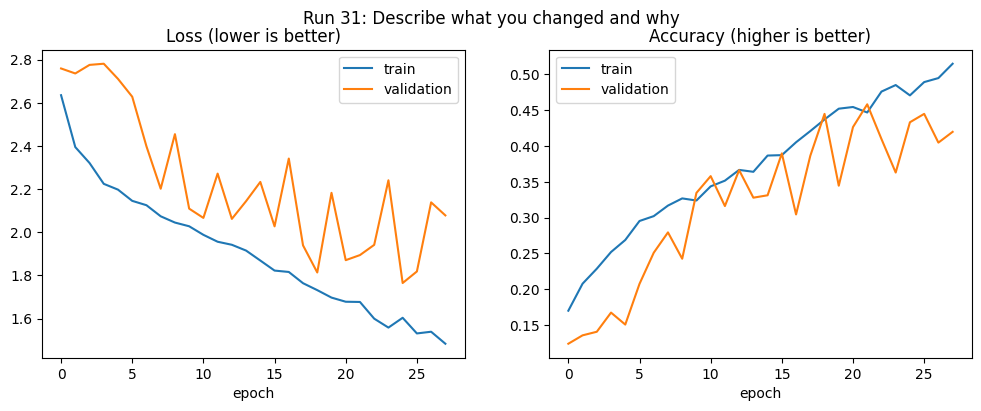

Run 31 | val_acc = 0.4582 | train_acc = 0.4468 | gap = -0.0114 | 0.5 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = True
cfg["learning_rate"] = 0.0024
cfg["batch_size"]=64
cfg["epoch"]=45
cfg["dropout"]=0.3
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
53/53 - 19s - 365ms/step - accuracy: 0.1787 - loss: 3.1047 - val_accuracy: 0.1304 - val_loss: 3.1882
Epoch 2/30
53/53 - 1s - 11ms/step - accuracy: 0.2330 - loss: 2.7840 - val_accuracy: 0.1237 - val_loss: 3.4631
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.2489 - loss: 2.6341 - val_accuracy: 0.0518 - val_loss: 4.1461
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.2740 - loss: 2.5250 - val_accuracy: 0.1237 - val_loss: 3.6342
Epoch 5/30
53/53 - 1s - 10ms/step - accuracy: 0.2725 - loss: 2.4735 - val_accuracy: 0.1789 - val_loss: 2.8422
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.2978 - loss: 2.3906 - val_accuracy: 0.1355 - val_loss: 3.5344
Epoch 7/30
53/53 - 1s - 11ms/step - accuracy: 0.3179 - loss: 2.3235 - val_accuracy: 0.1923 - val_loss: 3.0037
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.3394 - loss: 2.2348 - val_accuracy: 0.1957 - val_loss: 3.1330
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.3592 - loss: 2.2252 - val_accuracy: 0.2676 - val_loss: 2.5878
Epoch 10

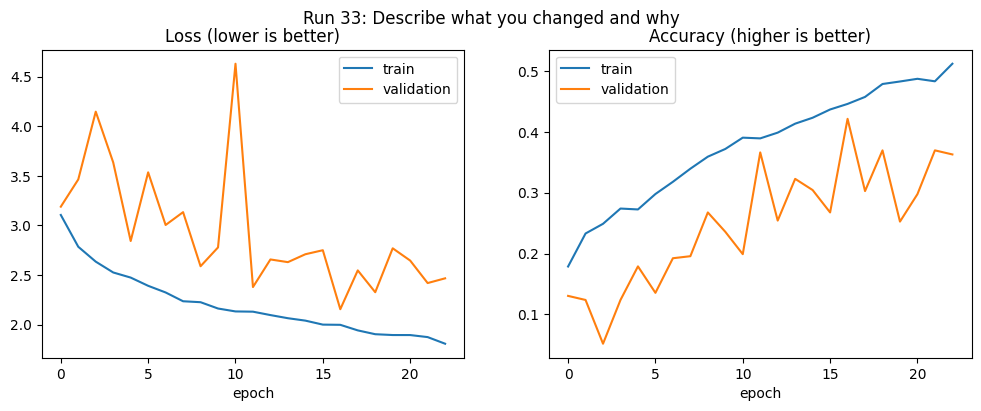

Run 33 | val_acc = 0.4214 | train_acc = 0.4459 | gap = 0.0245 | 0.5 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.0022
cfg["batch_size"]=64
cfg["epoch"]=45
cfg["dropout"]=0.3
cfg["l2"]=0.001
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
53/53 - 5s - 102ms/step - accuracy: 0.1814 - loss: 2.6695 - val_accuracy: 0.0719 - val_loss: 3.7070
Epoch 2/30
53/53 - 1s - 21ms/step - accuracy: 0.2123 - loss: 2.4408 - val_accuracy: 0.1388 - val_loss: 2.8772
Epoch 3/30
53/53 - 1s - 23ms/step - accuracy: 0.2356 - loss: 2.3603 - val_accuracy: 0.1722 - val_loss: 2.9581
Epoch 4/30
53/53 - 1s - 21ms/step - accuracy: 0.2457 - loss: 2.3124 - val_accuracy: 0.1505 - val_loss: 2.9244
Epoch 5/30
53/53 - 1s - 20ms/step - accuracy: 0.2648 - loss: 2.2674 - val_accuracy: 0.2191 - val_loss: 2.5291
Epoch 6/30
53/53 - 1s - 20ms/step - accuracy: 0.2993 - loss: 2.2362 - val_accuracy: 0.1706 - val_loss: 2.7003
Epoch 7/30
53/53 - 1s - 20ms/step - accuracy: 0.3008 - loss: 2.1974 - val_accuracy: 0.2358 - val_loss: 2.5350
Epoch 8/30
53/53 - 1s - 20ms/step - accuracy: 0.3200 - loss: 2.1686 - val_accuracy: 0.2425 - val_loss: 2.4643
Epoch 9/30
53/53 - 1s - 21ms/step - accuracy: 0.3244 - loss: 2.1136 - val_accuracy: 0.2776 - val_loss: 2.3773
Epoch 10/

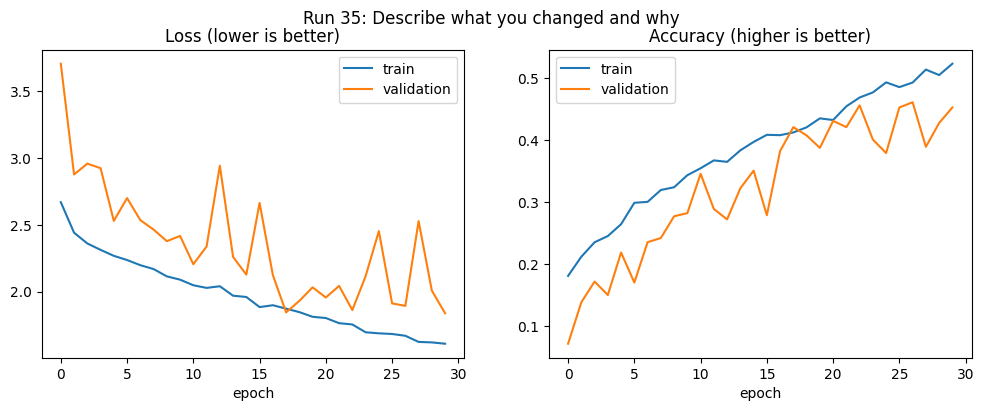

Run 35 | val_acc = 0.4615 | train_acc = 0.4934 | gap = 0.0318 | 0.6 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = True
cfg["learning_rate"] = 0.0022
cfg["batch_size"]=64
cfg["epoch"]=45
cfg["dropout"]=0.3
cfg["l2"]=0.0001
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
53/53 - 19s - 361ms/step - accuracy: 0.1778 - loss: 2.6053 - val_accuracy: 0.0836 - val_loss: 3.4185
Epoch 2/30
53/53 - 1s - 11ms/step - accuracy: 0.2274 - loss: 2.3525 - val_accuracy: 0.0853 - val_loss: 3.2374
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.2648 - loss: 2.2659 - val_accuracy: 0.1237 - val_loss: 3.2167
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.2866 - loss: 2.1755 - val_accuracy: 0.1171 - val_loss: 4.1013
Epoch 5/30
53/53 - 1s - 10ms/step - accuracy: 0.3150 - loss: 2.1336 - val_accuracy: 0.1756 - val_loss: 2.8761
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.3279 - loss: 2.0636 - val_accuracy: 0.2140 - val_loss: 3.0505
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.3495 - loss: 2.0069 - val_accuracy: 0.2525 - val_loss: 2.6250
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.3736 - loss: 1.9296 - val_accuracy: 0.2458 - val_loss: 2.5279
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.3863 - loss: 1.8758 - val_accuracy: 0.2341 - val_loss: 2.7612
Epoch 10

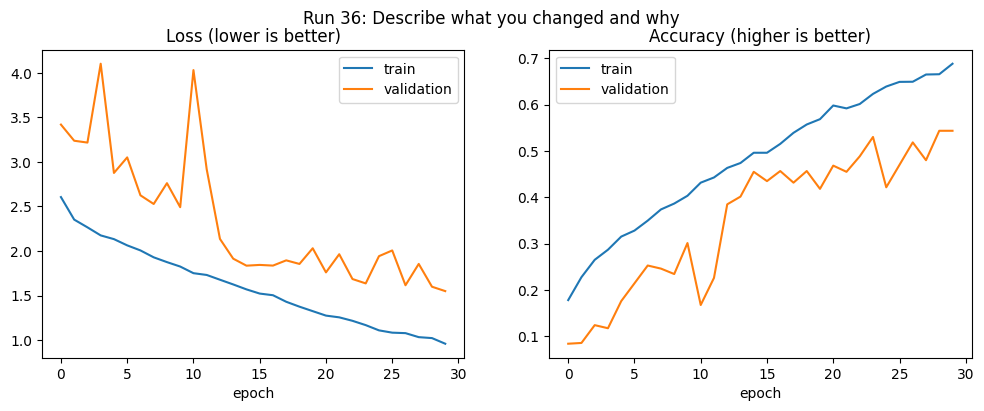

Run 36 | val_acc = 0.5435 | train_acc = 0.6656 | gap = 0.1221 | 0.6 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.0022
cfg["batch_size"]=64
cfg["epoch"]=45
cfg["dropout"]=0.3
cfg["l2"]=0.00002
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
53/53 - 24s - 461ms/step - accuracy: 0.1401 - loss: 2.8150 - val_accuracy: 0.1020 - val_loss: 2.6920
Epoch 2/30
53/53 - 1s - 14ms/step - accuracy: 0.1991 - loss: 2.4727 - val_accuracy: 0.1037 - val_loss: 3.2188
Epoch 3/30
53/53 - 1s - 12ms/step - accuracy: 0.2504 - loss: 2.3525 - val_accuracy: 0.1438 - val_loss: 3.0326
Epoch 4/30
53/53 - 1s - 13ms/step - accuracy: 0.2545 - loss: 2.3028 - val_accuracy: 0.1923 - val_loss: 3.2410
Epoch 5/30
53/53 - 1s - 12ms/step - accuracy: 0.2586 - loss: 2.2664 - val_accuracy: 0.2475 - val_loss: 2.5385
Epoch 6/30
53/53 - 1s - 12ms/step - accuracy: 0.2887 - loss: 2.1910 - val_accuracy: 0.1739 - val_loss: 4.4846
Epoch 7/30
53/53 - 1s - 12ms/step - accuracy: 0.3096 - loss: 2.1404 - val_accuracy: 0.2826 - val_loss: 2.2721
Epoch 8/30
53/53 - 1s - 12ms/step - accuracy: 0.3088 - loss: 2.0845 - val_accuracy: 0.2609 - val_loss: 2.4034
Epoch 9/30
53/53 - 1s - 12ms/step - accuracy: 0.3394 - loss: 2.0639 - val_accuracy: 0.2860 - val_loss: 2.3850
Epoch 10

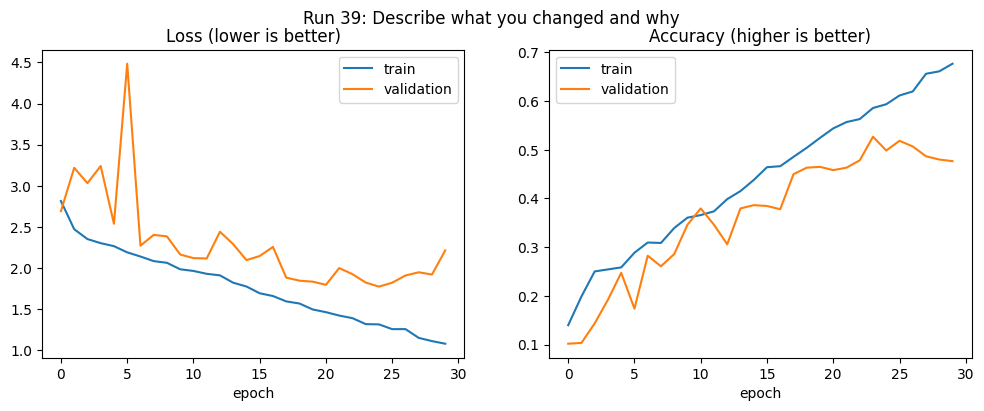

Run 39 | val_acc = 0.5268 | train_acc = 0.5857 | gap = 0.0589 | 0.7 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.0024
cfg["batch_size"]=64
cfg["epoch"]=40
cfg["dropout"]=0.3
cfg["l2"]=0.00002
cfg["num_blocks"]=4
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
53/53 - 9s - 161ms/step - accuracy: 0.1242 - loss: 2.8437 - val_accuracy: 0.0569 - val_loss: 3.1291
Epoch 2/30
53/53 - 2s - 30ms/step - accuracy: 0.2014 - loss: 2.4815 - val_accuracy: 0.1388 - val_loss: 2.9457
Epoch 3/30
53/53 - 2s - 29ms/step - accuracy: 0.2244 - loss: 2.3928 - val_accuracy: 0.1154 - val_loss: 2.9658
Epoch 4/30
53/53 - 1s - 28ms/step - accuracy: 0.2362 - loss: 2.3356 - val_accuracy: 0.1237 - val_loss: 3.0948
Epoch 5/30
53/53 - 1s - 24ms/step - accuracy: 0.2468 - loss: 2.2850 - val_accuracy: 0.2709 - val_loss: 2.3385
Epoch 6/30
53/53 - 1s - 23ms/step - accuracy: 0.2633 - loss: 2.2449 - val_accuracy: 0.2709 - val_loss: 2.3226
Epoch 7/30
53/53 - 1s - 24ms/step - accuracy: 0.2796 - loss: 2.2097 - val_accuracy: 0.2625 - val_loss: 2.2803
Epoch 8/30
53/53 - 1s - 23ms/step - accuracy: 0.2878 - loss: 2.1753 - val_accuracy: 0.2458 - val_loss: 2.3670
Epoch 9/30
53/53 - 1s - 23ms/step - accuracy: 0.2952 - loss: 2.1511 - val_accuracy: 0.2124 - val_loss: 2.6898
Epoch 10/

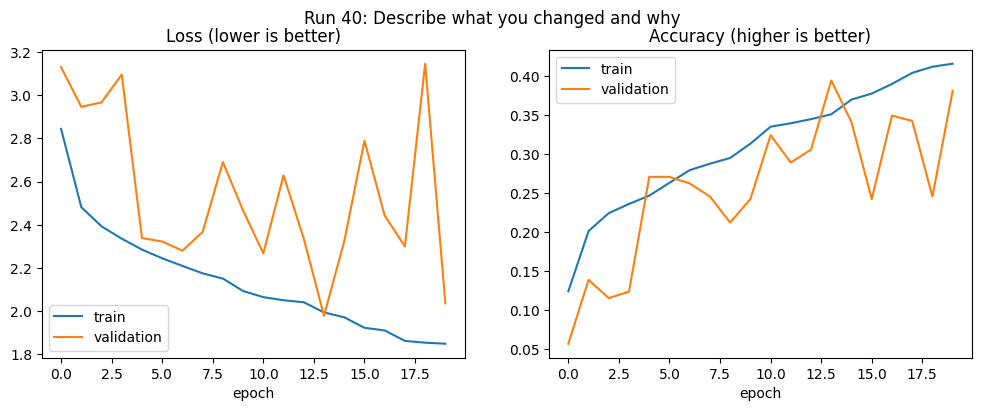

Run 40 | val_acc = 0.3946 | train_acc = 0.3512 | gap = -0.0434 | 0.6 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = True
cfg["learning_rate"] = 0.0022
cfg["batch_size"]=64
cfg["epoch"]=60
cfg["dropout"]=0.3
cfg["l2"]=0.00002
cfg["num_blocks"]=4
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
53/53 - 41s - 765ms/step - accuracy: 0.1277 - loss: 2.9661 - val_accuracy: 0.0803 - val_loss: 4.5384
Epoch 2/30
53/53 - 1s - 27ms/step - accuracy: 0.1646 - loss: 2.5779 - val_accuracy: 0.1555 - val_loss: 3.0635
Epoch 3/30
53/53 - 1s - 26ms/step - accuracy: 0.2014 - loss: 2.4788 - val_accuracy: 0.1221 - val_loss: 3.7659
Epoch 4/30
53/53 - 1s - 26ms/step - accuracy: 0.2291 - loss: 2.3916 - val_accuracy: 0.1087 - val_loss: 4.4408
Epoch 5/30
53/53 - 1s - 26ms/step - accuracy: 0.2347 - loss: 2.3393 - val_accuracy: 0.0886 - val_loss: 3.6783
Epoch 6/30
53/53 - 1s - 27ms/step - accuracy: 0.2554 - loss: 2.3004 - val_accuracy: 0.1555 - val_loss: 3.1758
Epoch 7/30
53/53 - 1s - 28ms/step - accuracy: 0.2513 - loss: 2.2742 - val_accuracy: 0.1973 - val_loss: 2.7247
Epoch 8/30
53/53 - 1s - 27ms/step - accuracy: 0.2775 - loss: 2.2176 - val_accuracy: 0.2207 - val_loss: 2.7116
Epoch 9/30
53/53 - 1s - 27ms/step - accuracy: 0.2884 - loss: 2.2033 - val_accuracy: 0.2575 - val_loss: 2.4102
Epoch 10

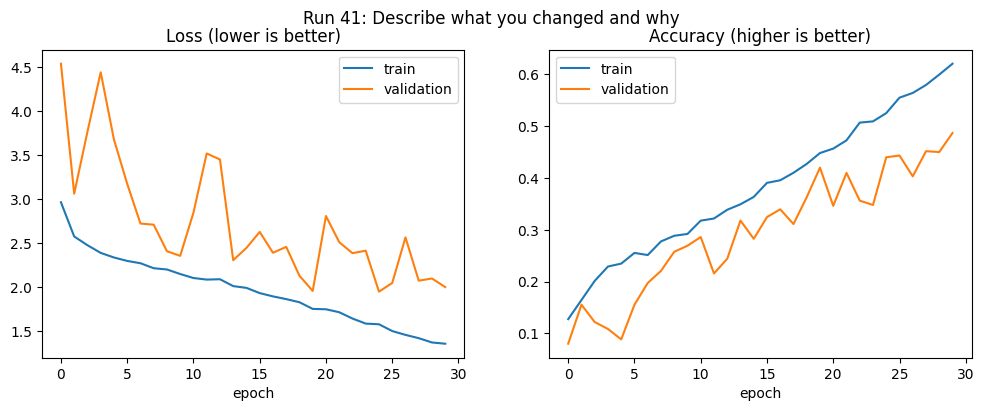

Run 41 | val_acc = 0.4866 | train_acc = 0.6202 | gap = 0.1335 | 1.4 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.0022
cfg["batch_size"]=64
cfg["epoch"]=60
cfg["dropout"]=0.25
cfg["l2"]=0.00002
cfg["num_blocks"]=4
cfg["base_filters"]=64
cfg["patience"]=10
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
53/53 - 20s - 372ms/step - accuracy: 0.1858 - loss: 2.6109 - val_accuracy: 0.1187 - val_loss: 3.0453
Epoch 2/30
53/53 - 1s - 11ms/step - accuracy: 0.2330 - loss: 2.3490 - val_accuracy: 0.1137 - val_loss: 3.0844
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.2510 - loss: 2.2769 - val_accuracy: 0.1555 - val_loss: 3.0620
Epoch 4/30
53/53 - 1s - 10ms/step - accuracy: 0.2787 - loss: 2.1792 - val_accuracy: 0.1254 - val_loss: 3.1697
Epoch 5/30
53/53 - 1s - 10ms/step - accuracy: 0.2852 - loss: 2.1615 - val_accuracy: 0.1672 - val_loss: 2.9446
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.3173 - loss: 2.0824 - val_accuracy: 0.2475 - val_loss: 2.3973
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.3497 - loss: 2.0075 - val_accuracy: 0.2977 - val_loss: 2.2319
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.3618 - loss: 1.9567 - val_accuracy: 0.2007 - val_loss: 2.6488
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.3725 - loss: 1.9264 - val_accuracy: 0.2609 - val_loss: 2.4596
Epoch 10

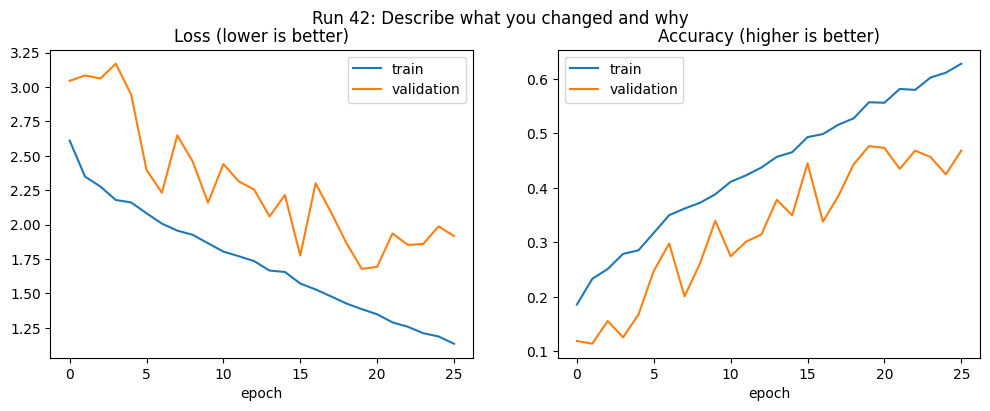

Run 42 | val_acc = 0.4766 | train_acc = 0.5571 | gap = 0.0805 | 0.6 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = False
cfg["learning_rate"] = 0.0024
cfg["batch_size"]=64
cfg["epoch"]=45
cfg["dropout"]=0.25
cfg["l2"]=0.00002
cfg["num_blocks"]=3
cfg["base_filters"]=32
cfg["patience"]=6
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
53/53 - 5s - 92ms/step - accuracy: 0.1646 - loss: 2.6044 - val_accuracy: 0.1020 - val_loss: 2.8669
Epoch 2/30
53/53 - 1s - 20ms/step - accuracy: 0.2241 - loss: 2.3422 - val_accuracy: 0.1338 - val_loss: 3.0182
Epoch 3/30
53/53 - 1s - 19ms/step - accuracy: 0.2566 - loss: 2.2605 - val_accuracy: 0.1137 - val_loss: 3.1838
Epoch 4/30
53/53 - 1s - 20ms/step - accuracy: 0.2636 - loss: 2.2014 - val_accuracy: 0.1371 - val_loss: 3.1009
Epoch 5/30
53/53 - 1s - 19ms/step - accuracy: 0.2704 - loss: 2.1896 - val_accuracy: 0.1823 - val_loss: 2.5118
Epoch 6/30
53/53 - 1s - 20ms/step - accuracy: 0.2893 - loss: 2.1472 - val_accuracy: 0.2174 - val_loss: 2.4309
Epoch 7/30
53/53 - 1s - 20ms/step - accuracy: 0.2990 - loss: 2.1122 - val_accuracy: 0.2943 - val_loss: 2.2359
Epoch 8/30
53/53 - 1s - 19ms/step - accuracy: 0.3129 - loss: 2.0598 - val_accuracy: 0.2826 - val_loss: 2.1599
Epoch 9/30
53/53 - 1s - 20ms/step - accuracy: 0.3335 - loss: 2.0358 - val_accuracy: 0.3043 - val_loss: 2.1385
Epoch 10/3

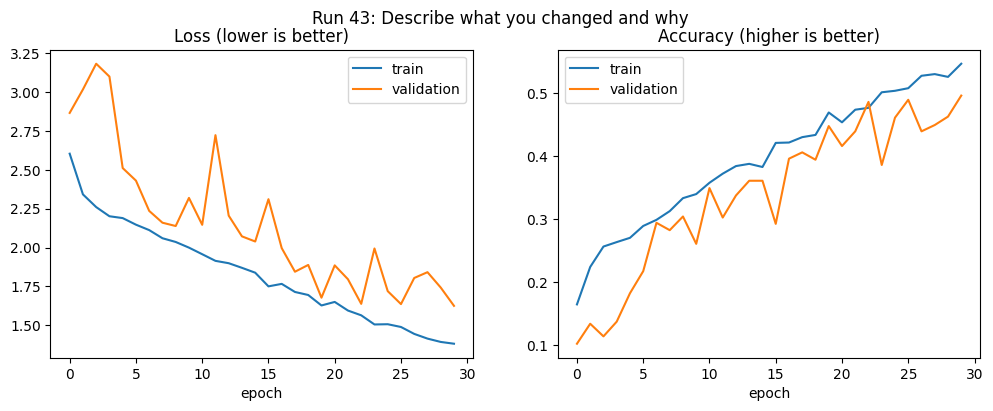

Run 43 | val_acc = 0.4967 | train_acc = 0.5473 | gap = 0.0507 | 0.6 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = True
cfg["learning_rate"] = 0.0024
cfg["batch_size"]=64
cfg["epoch"]=60
cfg["dropout"]=0.25
cfg["num_blocks"]=3
cfg["base_filters"]=32
cfg["patience"]=10
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
53/53 - 10s - 182ms/step - accuracy: 0.1846 - loss: 2.5734 - val_accuracy: 0.1221 - val_loss: 2.8573
Epoch 2/30
53/53 - 1s - 20ms/step - accuracy: 0.2315 - loss: 2.3402 - val_accuracy: 0.1070 - val_loss: 3.0695
Epoch 3/30
53/53 - 1s - 19ms/step - accuracy: 0.2607 - loss: 2.2631 - val_accuracy: 0.0987 - val_loss: 3.7145
Epoch 4/30
53/53 - 1s - 19ms/step - accuracy: 0.2766 - loss: 2.1957 - val_accuracy: 0.1154 - val_loss: 3.1498
Epoch 5/30
53/53 - 1s - 19ms/step - accuracy: 0.2976 - loss: 2.1369 - val_accuracy: 0.1472 - val_loss: 2.9799
Epoch 6/30
53/53 - 1s - 20ms/step - accuracy: 0.3147 - loss: 2.0963 - val_accuracy: 0.2040 - val_loss: 2.7669
Epoch 7/30
53/53 - 1s - 19ms/step - accuracy: 0.3244 - loss: 2.0520 - val_accuracy: 0.2324 - val_loss: 2.9120
Epoch 8/30
53/53 - 1s - 19ms/step - accuracy: 0.3415 - loss: 1.9904 - val_accuracy: 0.2793 - val_loss: 2.1967
Epoch 9/30
53/53 - 1s - 19ms/step - accuracy: 0.3424 - loss: 1.9728 - val_accuracy: 0.2659 - val_loss: 2.3266
Epoch 10

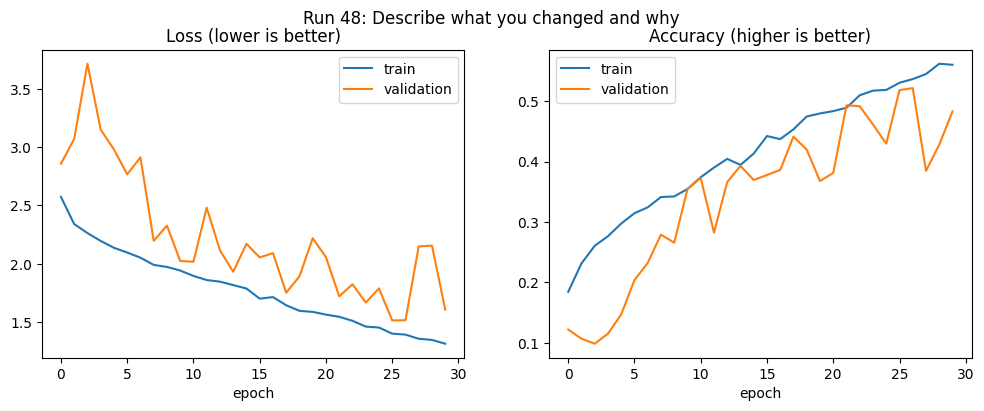

Run 48 | val_acc = 0.5217 | train_acc = 0.5367 | gap = 0.0150 | 0.7 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = True
cfg["learning_rate"] = 0.0024
cfg["batch_size"]=64
cfg["epoch"]=60
cfg["dropout"]=0.25
cfg["num_blocks"]=3
cfg["base_filters"]=32
cfg["patience"]=15
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/30
53/53 - 5s - 94ms/step - accuracy: 0.1834 - loss: 2.5888 - val_accuracy: 0.1488 - val_loss: 2.6313 - learning_rate: 0.0024
Epoch 2/30
53/53 - 1s - 20ms/step - accuracy: 0.2109 - loss: 2.3582 - val_accuracy: 0.1388 - val_loss: 3.0482 - learning_rate: 0.0024
Epoch 3/30
53/53 - 1s - 19ms/step - accuracy: 0.2412 - loss: 2.3065 - val_accuracy: 0.1438 - val_loss: 3.2584 - learning_rate: 0.0024
Epoch 4/30
53/53 - 1s - 20ms/step - accuracy: 0.2766 - loss: 2.1732 - val_accuracy: 0.1104 - val_loss: 3.3822 - learning_rate: 0.0012
Epoch 5/30
53/53 - 1s - 19ms/step - accuracy: 0.2875 - loss: 2.1370 - val_accuracy: 0.1003 - val_loss: 3.0412 - learning_rate: 0.0012
Epoch 6/30
53/53 - 1s - 19ms/step - accuracy: 0.3070 - loss: 2.0807 - val_accuracy: 0.1405 - val_loss: 3.1195 - learning_rate: 6.0000e-04
Epoch 7/30
53/53 - 1s - 19ms/step - accuracy: 0.3102 - loss: 2.0416 - val_accuracy: 0.1605 - val_loss: 2.8554 - learning_rate: 6.0000e-04
Epoch 8/30
53/53 - 1s - 19ms/step - accuracy: 0.3368 -

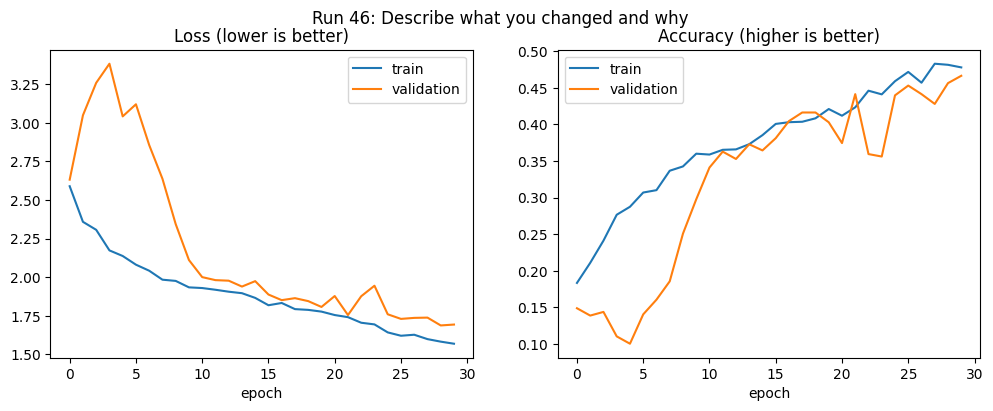

Run 46 | val_acc = 0.4666 | train_acc = 0.4780 | gap = 0.0115 | 0.6 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = True
cfg["learning_rate"] = 0.0024
cfg["batch_size"]=64
cfg["epoch"]=60
cfg["dropout"]=0.25
cfg["num_blocks"]=3
cfg["base_filters"]=32
cfg["patience"]=15
cfg["use_lr_schedule"]=True
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/60
53/53 - 5s - 95ms/step - accuracy: 0.1811 - loss: 2.5896 - val_accuracy: 0.1054 - val_loss: 2.9773
Epoch 2/60
53/53 - 1s - 20ms/step - accuracy: 0.2191 - loss: 2.3808 - val_accuracy: 0.1137 - val_loss: 3.2189
Epoch 3/60
53/53 - 1s - 21ms/step - accuracy: 0.2486 - loss: 2.2948 - val_accuracy: 0.1137 - val_loss: 3.3299
Epoch 4/60
53/53 - 1s - 20ms/step - accuracy: 0.2628 - loss: 2.2244 - val_accuracy: 0.1388 - val_loss: 3.1969
Epoch 5/60
53/53 - 1s - 20ms/step - accuracy: 0.2781 - loss: 2.1991 - val_accuracy: 0.2007 - val_loss: 2.9168
Epoch 6/60
53/53 - 1s - 20ms/step - accuracy: 0.2928 - loss: 2.1674 - val_accuracy: 0.2391 - val_loss: 2.4646
Epoch 7/60
53/53 - 1s - 20ms/step - accuracy: 0.2973 - loss: 2.1231 - val_accuracy: 0.2559 - val_loss: 2.4222
Epoch 8/60
53/53 - 1s - 19ms/step - accuracy: 0.3043 - loss: 2.0870 - val_accuracy: 0.2542 - val_loss: 2.2553
Epoch 9/60
53/53 - 1s - 20ms/step - accuracy: 0.3206 - loss: 2.0457 - val_accuracy: 0.2625 - val_loss: 2.4107
Epoch 10/6

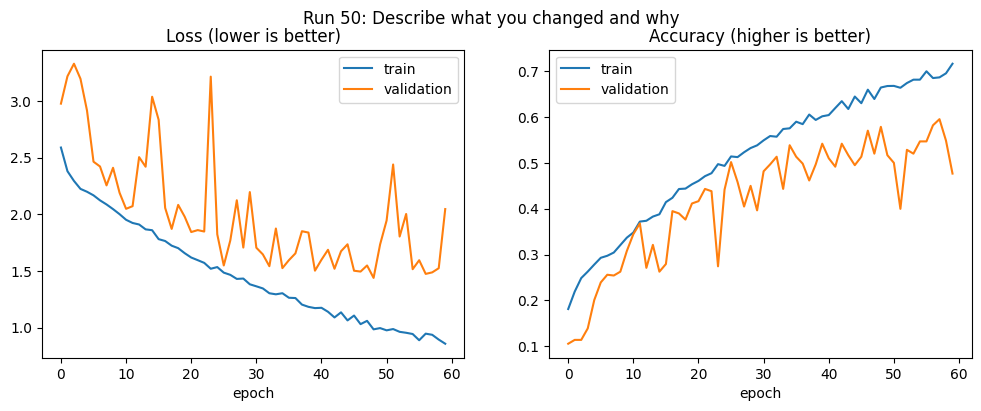

Run 50 | val_acc = 0.5953 | train_acc = 0.6865 | gap = 0.0912 | 1.1 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = True
cfg["learning_rate"] = 0.0026
cfg["batch_size"]=64
cfg["epochs"]=60
cfg["dropout"]=0.25
cfg["num_blocks"]=3
cfg["base_filters"]=32
cfg["patience"]=15
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/60
53/53 - 7s - 139ms/step - accuracy: 0.1660 - loss: 2.6611 - val_accuracy: 0.1505 - val_loss: 3.0715
Epoch 2/60
53/53 - 2s - 32ms/step - accuracy: 0.2038 - loss: 2.4130 - val_accuracy: 0.1789 - val_loss: 2.9434
Epoch 3/60
53/53 - 2s - 32ms/step - accuracy: 0.2250 - loss: 2.3328 - val_accuracy: 0.1472 - val_loss: 3.4435
Epoch 4/60
53/53 - 2s - 32ms/step - accuracy: 0.2583 - loss: 2.2581 - val_accuracy: 0.1656 - val_loss: 2.9862
Epoch 5/60
53/53 - 2s - 33ms/step - accuracy: 0.2595 - loss: 2.2374 - val_accuracy: 0.1940 - val_loss: 2.6383
Epoch 6/60
53/53 - 2s - 34ms/step - accuracy: 0.2766 - loss: 2.2023 - val_accuracy: 0.2508 - val_loss: 2.2720
Epoch 7/60
53/53 - 2s - 33ms/step - accuracy: 0.2852 - loss: 2.1687 - val_accuracy: 0.2492 - val_loss: 2.2560
Epoch 8/60
53/53 - 2s - 33ms/step - accuracy: 0.2993 - loss: 2.1235 - val_accuracy: 0.2926 - val_loss: 2.3067
Epoch 9/60
53/53 - 2s - 33ms/step - accuracy: 0.3014 - loss: 2.1096 - val_accuracy: 0.2676 - val_loss: 2.2330
Epoch 10/

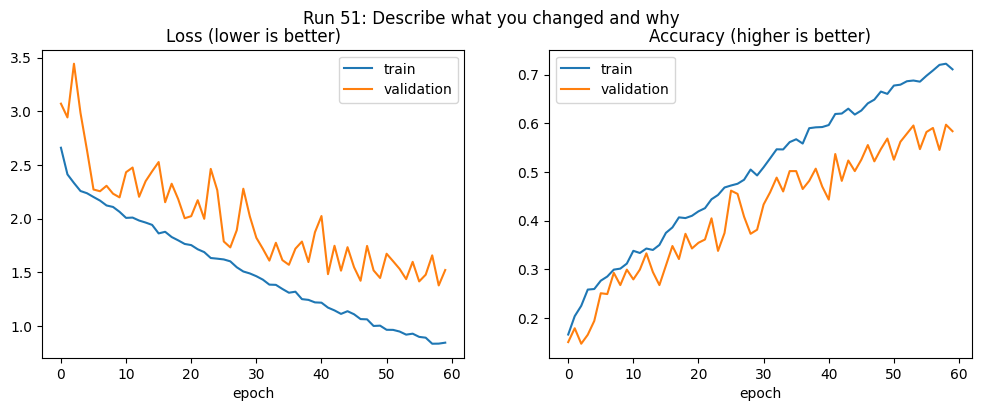

Run 51 | val_acc = 0.5970 | train_acc = 0.7222 | gap = 0.1252 | 1.8 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = True
cfg["learning_rate"] = 0.0026
cfg["batch_size"]=64
cfg["epochs"]=60
cfg["dropout"]=0.25
cfg["num_blocks"]=3
cfg["base_filters"]=64
cfg["patience"]=15
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/60
53/53 - 6s - 111ms/step - accuracy: 0.1640 - loss: 2.6558 - val_accuracy: 0.0970 - val_loss: 3.7895
Epoch 2/60
53/53 - 2s - 33ms/step - accuracy: 0.2038 - loss: 2.4149 - val_accuracy: 0.1923 - val_loss: 2.6646
Epoch 3/60
53/53 - 2s - 32ms/step - accuracy: 0.2288 - loss: 2.3371 - val_accuracy: 0.1622 - val_loss: 2.9964
Epoch 4/60
53/53 - 2s - 33ms/step - accuracy: 0.2454 - loss: 2.2900 - val_accuracy: 0.1522 - val_loss: 3.0146
Epoch 5/60
53/53 - 2s - 33ms/step - accuracy: 0.2719 - loss: 2.2329 - val_accuracy: 0.2007 - val_loss: 2.5999
Epoch 6/60
53/53 - 2s - 33ms/step - accuracy: 0.2902 - loss: 2.1960 - val_accuracy: 0.2375 - val_loss: 2.3983
Epoch 7/60
53/53 - 2s - 33ms/step - accuracy: 0.2905 - loss: 2.1599 - val_accuracy: 0.2542 - val_loss: 2.2752
Epoch 8/60
53/53 - 2s - 33ms/step - accuracy: 0.2976 - loss: 2.1239 - val_accuracy: 0.2709 - val_loss: 2.2383
Epoch 9/60
53/53 - 2s - 33ms/step - accuracy: 0.2976 - loss: 2.1025 - val_accuracy: 0.2726 - val_loss: 2.2777
Epoch 10/

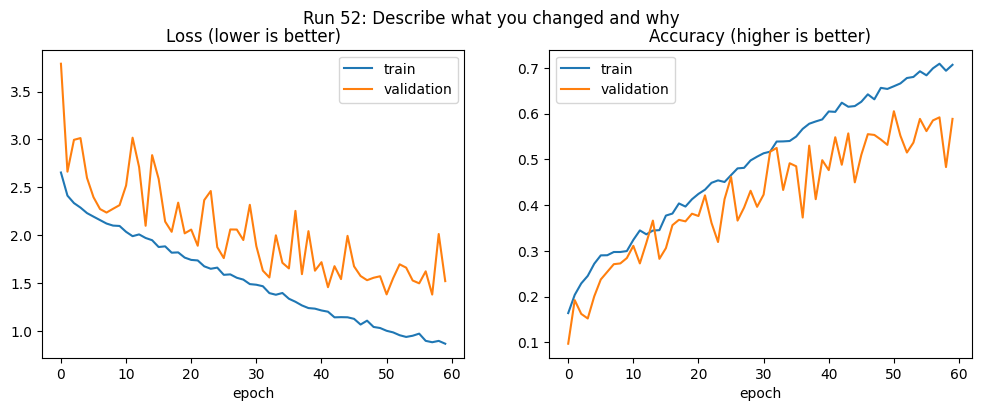

Run 52 | val_acc = 0.6054 | train_acc = 0.6600 | gap = 0.0546 | 1.8 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = True
cfg["learning_rate"] = 0.0026
cfg["batch_size"]=64
cfg["epochs"]=60
cfg["dropout"]=0.3
cfg["num_blocks"]=3
cfg["base_filters"]=64
cfg["patience"]=15
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/60
53/53 - 6s - 115ms/step - accuracy: 0.1643 - loss: 2.6788 - val_accuracy: 0.0836 - val_loss: 3.0441
Epoch 2/60
53/53 - 2s - 33ms/step - accuracy: 0.2179 - loss: 2.3982 - val_accuracy: 0.1455 - val_loss: 3.0852
Epoch 3/60
53/53 - 2s - 33ms/step - accuracy: 0.2430 - loss: 2.3056 - val_accuracy: 0.0853 - val_loss: 3.4807
Epoch 4/60
53/53 - 2s - 33ms/step - accuracy: 0.2592 - loss: 2.2550 - val_accuracy: 0.1438 - val_loss: 2.8934
Epoch 5/60
53/53 - 2s - 33ms/step - accuracy: 0.2772 - loss: 2.2190 - val_accuracy: 0.1890 - val_loss: 2.4722
Epoch 6/60
53/53 - 2s - 33ms/step - accuracy: 0.2878 - loss: 2.1975 - val_accuracy: 0.1806 - val_loss: 2.7872
Epoch 7/60
53/53 - 2s - 34ms/step - accuracy: 0.3011 - loss: 2.1608 - val_accuracy: 0.2274 - val_loss: 2.7190
Epoch 8/60
53/53 - 2s - 33ms/step - accuracy: 0.3035 - loss: 2.1429 - val_accuracy: 0.2759 - val_loss: 2.1586
Epoch 9/60
53/53 - 2s - 33ms/step - accuracy: 0.2993 - loss: 2.1445 - val_accuracy: 0.2508 - val_loss: 2.3001
Epoch 10/

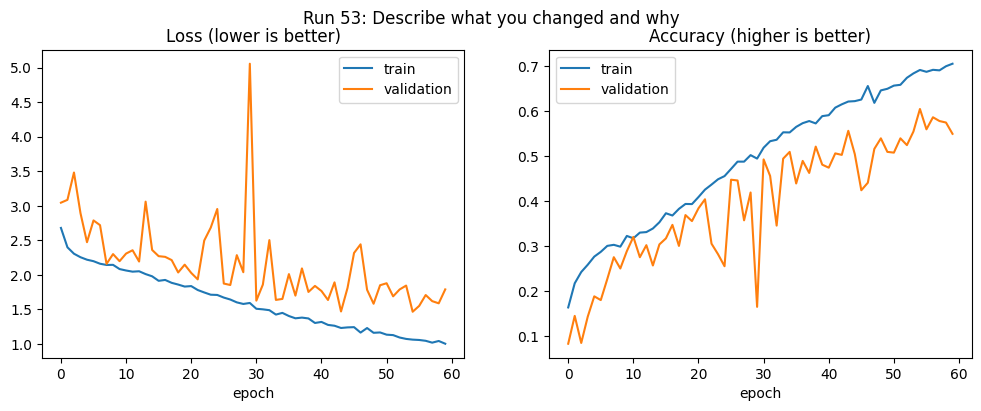

Run 53 | val_acc = 0.6054 | train_acc = 0.6921 | gap = 0.0868 | 1.8 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = True
cfg["learning_rate"] = 0.0026
cfg["batch_size"]=64
cfg["epochs"]=60
cfg["dropout"]=0.28
cfg["num_blocks"]=3
cfg["base_filters"]=64
cfg["patience"]=15
cfg["l2"]=0.00001
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/60
53/53 - 6s - 118ms/step - accuracy: 0.1672 - loss: 2.6826 - val_accuracy: 0.1037 - val_loss: 3.5956
Epoch 2/60
53/53 - 2s - 32ms/step - accuracy: 0.2135 - loss: 2.3908 - val_accuracy: 0.1271 - val_loss: 3.0794
Epoch 3/60
53/53 - 2s - 33ms/step - accuracy: 0.2398 - loss: 2.3275 - val_accuracy: 0.1271 - val_loss: 3.1625
Epoch 4/60
53/53 - 2s - 33ms/step - accuracy: 0.2622 - loss: 2.2607 - val_accuracy: 0.1572 - val_loss: 2.9976
Epoch 5/60
53/53 - 2s - 33ms/step - accuracy: 0.2554 - loss: 2.2627 - val_accuracy: 0.1973 - val_loss: 2.5541
Epoch 6/60
53/53 - 2s - 34ms/step - accuracy: 0.2843 - loss: 2.2139 - val_accuracy: 0.2375 - val_loss: 2.3494
Epoch 7/60
53/53 - 2s - 33ms/step - accuracy: 0.2970 - loss: 2.1729 - val_accuracy: 0.2742 - val_loss: 2.3970
Epoch 8/60
53/53 - 2s - 32ms/step - accuracy: 0.2893 - loss: 2.1568 - val_accuracy: 0.2659 - val_loss: 2.2255
Epoch 9/60
53/53 - 2s - 33ms/step - accuracy: 0.2978 - loss: 2.1253 - val_accuracy: 0.2793 - val_loss: 2.2529
Epoch 10/

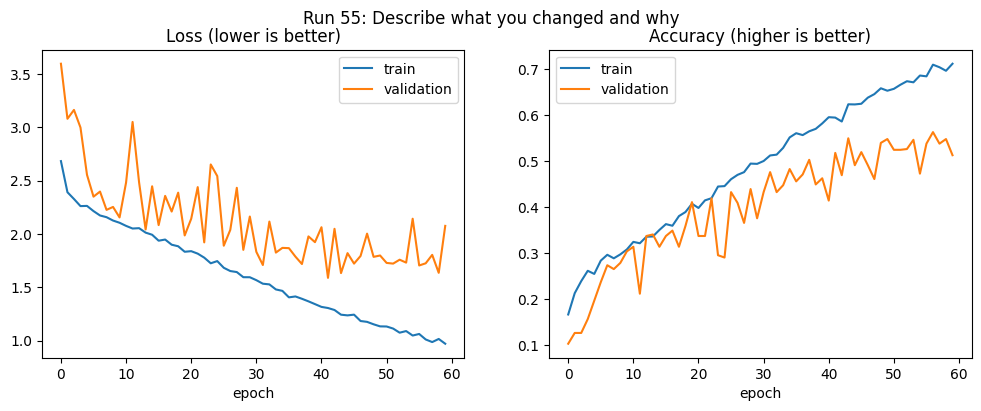

Run 55 | val_acc = 0.5635 | train_acc = 0.7101 | gap = 0.1466 | 1.8 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = True
cfg["learning_rate"] = 0.0026
cfg["batch_size"]=64
cfg["epochs"]=60
cfg["dropout"]=0.25
cfg["num_blocks"]=3
cfg["base_filters"]=64
cfg["patience"]=15
cfg["optimizer"]="adamw"
cfg["l2"]=0.00001
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/60
53/53 - 6s - 119ms/step - accuracy: 0.1657 - loss: 2.6793 - val_accuracy: 0.1237 - val_loss: 2.7051
Epoch 2/60
53/53 - 2s - 33ms/step - accuracy: 0.2176 - loss: 2.4002 - val_accuracy: 0.1171 - val_loss: 3.3302
Epoch 3/60
53/53 - 2s - 33ms/step - accuracy: 0.2465 - loss: 2.3149 - val_accuracy: 0.1488 - val_loss: 3.2988
Epoch 4/60
53/53 - 2s - 33ms/step - accuracy: 0.2548 - loss: 2.2688 - val_accuracy: 0.1388 - val_loss: 3.2725
Epoch 5/60
53/53 - 2s - 33ms/step - accuracy: 0.2595 - loss: 2.2327 - val_accuracy: 0.2241 - val_loss: 2.3979
Epoch 6/60
53/53 - 2s - 33ms/step - accuracy: 0.2804 - loss: 2.2081 - val_accuracy: 0.2157 - val_loss: 2.3520
Epoch 7/60
53/53 - 2s - 33ms/step - accuracy: 0.2843 - loss: 2.1766 - val_accuracy: 0.3060 - val_loss: 2.2671
Epoch 8/60
53/53 - 2s - 33ms/step - accuracy: 0.2961 - loss: 2.1352 - val_accuracy: 0.2776 - val_loss: 2.1892
Epoch 9/60
53/53 - 2s - 33ms/step - accuracy: 0.2928 - loss: 2.1314 - val_accuracy: 0.2542 - val_loss: 2.3510
Epoch 10/

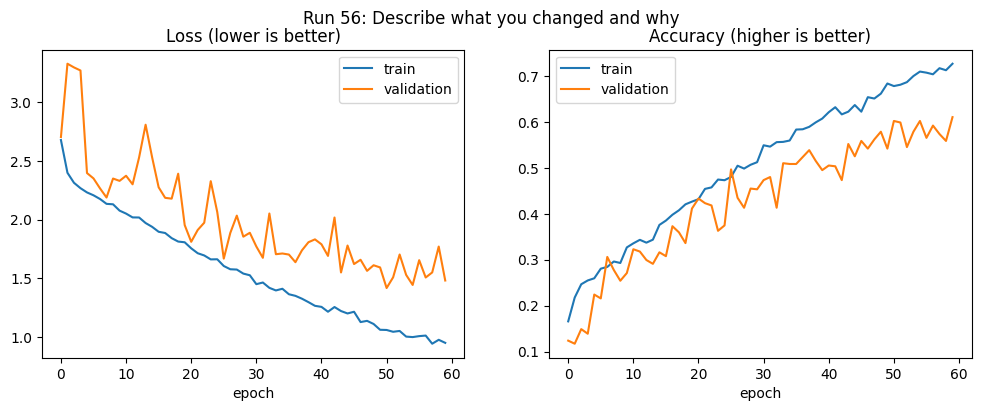

Run 56 | val_acc = 0.6104 | train_acc = 0.7266 | gap = 0.1163 | 1.8 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = True
cfg["learning_rate"] = 0.0026
cfg["batch_size"]=64
cfg["epochs"]=60
cfg["dropout"]=0.28
cfg["num_blocks"]=3
cfg["base_filters"]=64
cfg["patience"]=15
cfg["optimizer"]="adamw"
cfg["l2"]=0.00001
model = run_experiment(cfg, notes="Describe what you changed and why")

Epoch 1/75
53/53 - 6s - 119ms/step - accuracy: 0.1604 - loss: 2.7071 - val_accuracy: 0.1187 - val_loss: 2.8843
Epoch 2/75
53/53 - 2s - 33ms/step - accuracy: 0.2041 - loss: 2.4271 - val_accuracy: 0.1154 - val_loss: 3.2048
Epoch 3/75
53/53 - 2s - 33ms/step - accuracy: 0.2294 - loss: 2.3526 - val_accuracy: 0.1187 - val_loss: 3.1912
Epoch 4/75
53/53 - 2s - 34ms/step - accuracy: 0.2630 - loss: 2.2856 - val_accuracy: 0.1271 - val_loss: 3.1967
Epoch 5/75
53/53 - 2s - 34ms/step - accuracy: 0.2560 - loss: 2.2603 - val_accuracy: 0.1923 - val_loss: 2.6422
Epoch 6/75
53/53 - 2s - 33ms/step - accuracy: 0.2751 - loss: 2.2276 - val_accuracy: 0.1722 - val_loss: 2.7301
Epoch 7/75
53/53 - 2s - 34ms/step - accuracy: 0.2902 - loss: 2.1843 - val_accuracy: 0.2910 - val_loss: 2.1994
Epoch 8/75
53/53 - 2s - 34ms/step - accuracy: 0.2964 - loss: 2.1511 - val_accuracy: 0.2926 - val_loss: 2.2571
Epoch 9/75
53/53 - 2s - 33ms/step - accuracy: 0.2943 - loss: 2.1591 - val_accuracy: 0.2542 - val_loss: 2.2709
Epoch 10/

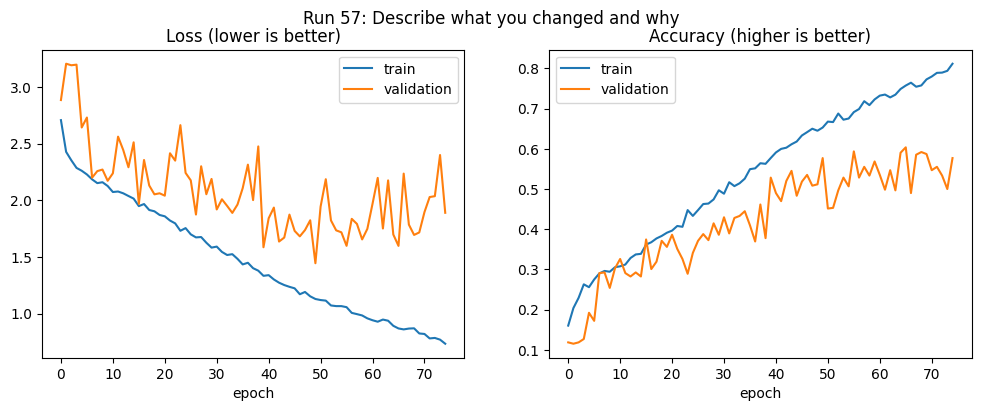

Run 57 | val_acc = 0.6037 | train_acc = 0.7573 | gap = 0.1536 | 2.3 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = True
cfg["learning_rate"] = 0.0026
cfg["batch_size"]=64
cfg["epochs"]=75
cfg["dropout"]=0.28
cfg["num_blocks"]=3
cfg["base_filters"]=64
cfg["patience"]=15
cfg["optimizer"]="adamw"
cfg["l2"]=0.00001
cfg["dense_units"]=512
model = run_experiment(cfg, notes="Describe what you changed and why")


Epoch 1/75
53/53 - 6s - 120ms/step - accuracy: 0.1457 - loss: 2.7937 - val_accuracy: 0.1037 - val_loss: 2.7263
Epoch 2/75
53/53 - 2s - 33ms/step - accuracy: 0.1994 - loss: 2.4758 - val_accuracy: 0.0819 - val_loss: 3.7294
Epoch 3/75
53/53 - 2s - 34ms/step - accuracy: 0.2197 - loss: 2.4005 - val_accuracy: 0.1154 - val_loss: 3.4347
Epoch 4/75
53/53 - 2s - 35ms/step - accuracy: 0.2400 - loss: 2.3372 - val_accuracy: 0.1304 - val_loss: 3.2169
Epoch 5/75
53/53 - 2s - 34ms/step - accuracy: 0.2630 - loss: 2.2817 - val_accuracy: 0.1973 - val_loss: 2.4764
Epoch 6/75
53/53 - 2s - 34ms/step - accuracy: 0.2622 - loss: 2.2520 - val_accuracy: 0.1773 - val_loss: 2.7036
Epoch 7/75
53/53 - 2s - 34ms/step - accuracy: 0.2692 - loss: 2.2314 - val_accuracy: 0.2977 - val_loss: 2.4094
Epoch 8/75
53/53 - 2s - 33ms/step - accuracy: 0.2852 - loss: 2.1882 - val_accuracy: 0.2960 - val_loss: 2.1570
Epoch 9/75
53/53 - 2s - 34ms/step - accuracy: 0.2849 - loss: 2.1821 - val_accuracy: 0.2826 - val_loss: 2.2071
Epoch 10/

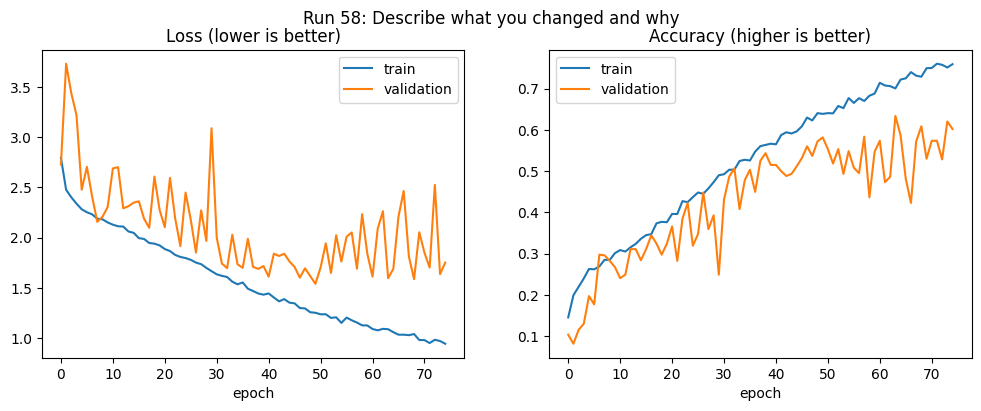

Run 58 | val_acc = 0.6338 | train_acc = 0.7004 | gap = 0.0666 | 2.3 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = True
cfg["learning_rate"] = 0.0026
cfg["batch_size"]=64
cfg["epochs"]=75
cfg["dropout"]=0.32
cfg["num_blocks"]=3
cfg["base_filters"]=64
cfg["patience"]=15
cfg["optimizer"]="adamw"
cfg["l2"]=0.00002
cfg["dense_units"]=512
model = run_experiment(cfg, notes="Describe what you changed and why")


Epoch 1/75
53/53 - 7s - 127ms/step - accuracy: 0.1663 - loss: 2.6644 - val_accuracy: 0.1371 - val_loss: 3.5679
Epoch 2/75
53/53 - 2s - 33ms/step - accuracy: 0.2103 - loss: 2.4194 - val_accuracy: 0.2174 - val_loss: 2.6280
Epoch 3/75
53/53 - 2s - 33ms/step - accuracy: 0.2374 - loss: 2.3661 - val_accuracy: 0.1338 - val_loss: 2.9269
Epoch 4/75
53/53 - 2s - 33ms/step - accuracy: 0.2465 - loss: 2.2987 - val_accuracy: 0.1739 - val_loss: 2.7193
Epoch 5/75
53/53 - 2s - 33ms/step - accuracy: 0.2554 - loss: 2.2765 - val_accuracy: 0.1371 - val_loss: 3.0139
Epoch 6/75
53/53 - 2s - 34ms/step - accuracy: 0.2657 - loss: 2.2605 - val_accuracy: 0.2475 - val_loss: 2.3497
Epoch 7/75
53/53 - 2s - 33ms/step - accuracy: 0.2908 - loss: 2.2059 - val_accuracy: 0.2826 - val_loss: 2.2365
Epoch 8/75
53/53 - 2s - 33ms/step - accuracy: 0.2887 - loss: 2.1739 - val_accuracy: 0.2709 - val_loss: 2.3310
Epoch 9/75
53/53 - 2s - 34ms/step - accuracy: 0.2934 - loss: 2.1645 - val_accuracy: 0.2926 - val_loss: 2.1941
Epoch 10/

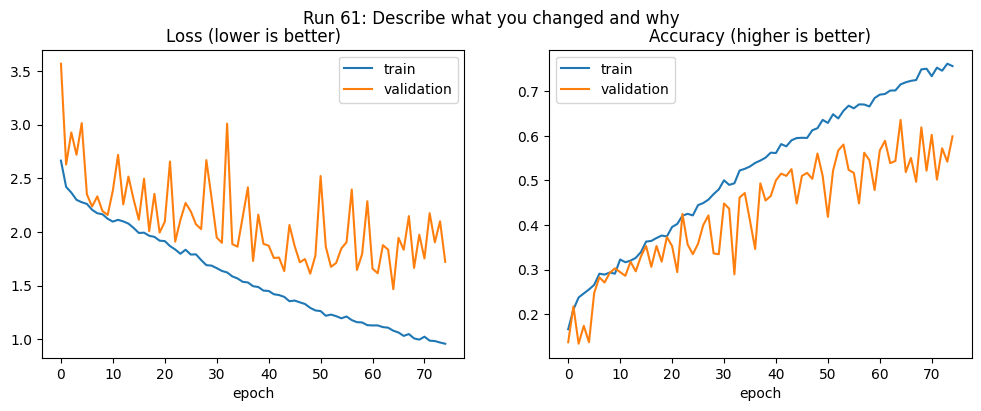

Run 61 | val_acc = 0.6355 | train_acc = 0.7151 | gap = 0.0797 | 2.3 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = True
cfg["learning_rate"] = 0.0026
cfg["batch_size"]=64
cfg["epochs"]=75
cfg["dropout"]=0.32
cfg["num_blocks"]=3
cfg["base_filters"]=64
cfg["patience"]=15
cfg["optimizer"]="adamw"
cfg["l2"]=0.00002
cfg["dense_units"]=512
model = run_experiment(cfg, notes="Describe what you changed and why")


Epoch 1/75
53/53 - 6s - 118ms/step - accuracy: 0.1719 - loss: 2.6870 - val_accuracy: 0.1120 - val_loss: 3.5785
Epoch 2/75
53/53 - 2s - 33ms/step - accuracy: 0.2050 - loss: 2.4280 - val_accuracy: 0.1237 - val_loss: 2.9506
Epoch 3/75
53/53 - 2s - 33ms/step - accuracy: 0.2283 - loss: 2.3767 - val_accuracy: 0.1338 - val_loss: 3.2659
Epoch 4/75
53/53 - 2s - 33ms/step - accuracy: 0.2430 - loss: 2.3203 - val_accuracy: 0.1237 - val_loss: 3.1603
Epoch 5/75
53/53 - 2s - 33ms/step - accuracy: 0.2607 - loss: 2.2955 - val_accuracy: 0.1572 - val_loss: 2.6105
Epoch 6/75
53/53 - 2s - 33ms/step - accuracy: 0.2731 - loss: 2.2404 - val_accuracy: 0.1538 - val_loss: 2.7971
Epoch 7/75
53/53 - 3s - 48ms/step - accuracy: 0.2816 - loss: 2.2139 - val_accuracy: 0.2492 - val_loss: 2.6430
Epoch 8/75
53/53 - 2s - 34ms/step - accuracy: 0.2825 - loss: 2.1867 - val_accuracy: 0.2759 - val_loss: 2.2951
Epoch 9/75
53/53 - 2s - 33ms/step - accuracy: 0.2928 - loss: 2.1799 - val_accuracy: 0.2776 - val_loss: 2.2559
Epoch 10/

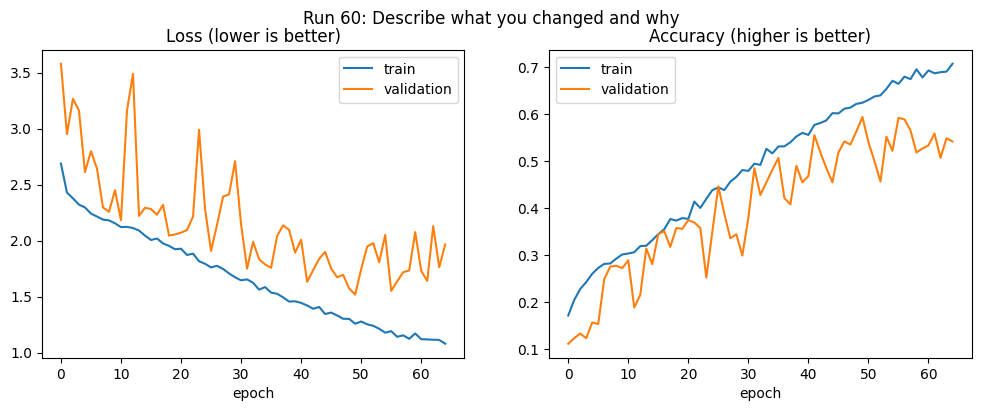

Run 60 | val_acc = 0.5936 | train_acc = 0.6240 | gap = 0.0304 | 2.0 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = True
cfg["learning_rate"] = 0.0024
cfg["batch_size"]=64
cfg["epochs"]=75
cfg["dropout"]=0.35
cfg["num_blocks"]=3
cfg["base_filters"]=64
cfg["patience"]=15
cfg["optimizer"]="adamw"
cfg["l2"]=0.00002
cfg["dense_units"]=512
model = run_experiment(cfg, notes="Describe what you changed and why")


Epoch 1/75
53/53 - 7s - 132ms/step - accuracy: 0.1463 - loss: 2.7648 - val_accuracy: 0.1204 - val_loss: 3.6580
Epoch 2/75
53/53 - 2s - 33ms/step - accuracy: 0.1996 - loss: 2.4477 - val_accuracy: 0.1421 - val_loss: 2.9991
Epoch 3/75
53/53 - 2s - 33ms/step - accuracy: 0.2256 - loss: 2.3980 - val_accuracy: 0.1522 - val_loss: 3.3613
Epoch 4/75
53/53 - 2s - 33ms/step - accuracy: 0.2350 - loss: 2.3442 - val_accuracy: 0.1304 - val_loss: 3.4394
Epoch 5/75
53/53 - 2s - 33ms/step - accuracy: 0.2359 - loss: 2.3176 - val_accuracy: 0.2023 - val_loss: 2.5920
Epoch 6/75
53/53 - 2s - 33ms/step - accuracy: 0.2566 - loss: 2.2941 - val_accuracy: 0.1957 - val_loss: 2.4693
Epoch 7/75
53/53 - 2s - 33ms/step - accuracy: 0.2734 - loss: 2.2390 - val_accuracy: 0.2759 - val_loss: 2.4051
Epoch 8/75
53/53 - 2s - 32ms/step - accuracy: 0.2790 - loss: 2.2014 - val_accuracy: 0.2726 - val_loss: 2.2106
Epoch 9/75
53/53 - 2s - 33ms/step - accuracy: 0.2825 - loss: 2.1989 - val_accuracy: 0.2358 - val_loss: 2.3688
Epoch 10/

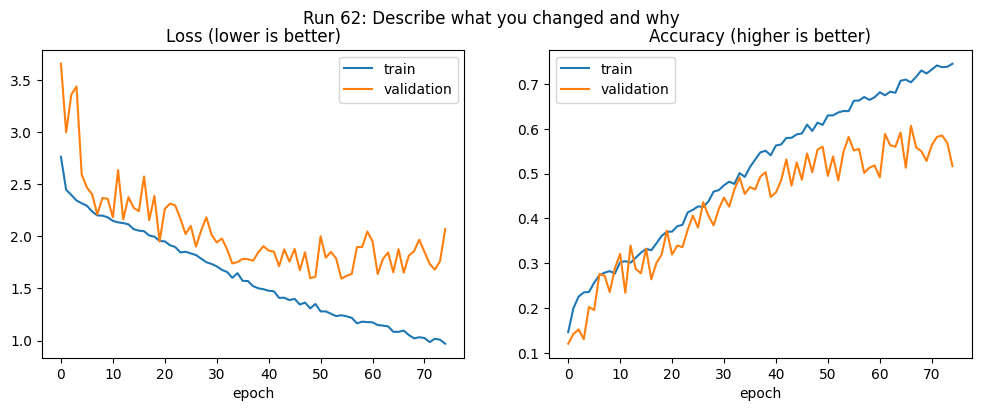

Run 62 | val_acc = 0.6070 | train_acc = 0.7039 | gap = 0.0969 | 2.3 min


In [ ]:
cfg = dict(baseline_cfg)
cfg["augment"] = True
cfg["learning_rate"] = 0.0026
cfg["batch_size"]=64
cfg["epochs"]=75
cfg["dropout"]=0.32
cfg["num_blocks"]=3
cfg["base_filters"]=64
cfg["patience"]=15
cfg["optimizer"]="adamw"
cfg["l2"]=0.00002
cfg["dense_units"]=512
model = run_experiment(cfg, notes="Describe what you changed and why")


## Step 6: Your results table

This is your lab notebook. Look for patterns: which settings help, which hurt, which hardly matter. Copy the most interesting rows into the table in your README or report, and write one sentence about what you learned from each.

,run,notes,learning_rate,batch_size,optimizer,dropout,l2,base_filters,num_blocks,dense_units,augment,use_lr_schedule,train_acc,val_acc,gap,best_epoch,minutes
0,61,Describe what you changed and why,0.0026,64,adamw,0.32,0.00002,64,3,512,True,False,0.7151,0.6355,0.0797,65,2.3
1,58,Describe what you changed and why,0.0026,64,adamw,0.32,0.00002,64,3,512,True,False,0.7004,0.6338,0.0666,64,2.3
2,56,Describe what you changed and why,0.0026,64,adamw,0.28,0.00001,64,3,256,True,False,0.7266,0.6104,0.1163,60,1.8
3,62,Describe what you changed and why,0.0026,64,adamw,0.32,0.00002,64,3,512,True,False,0.7039,0.6070,0.0969,67,2.3
4,53,Describe what you changed and why,0.0026,64,adam,0.28,0.00001,64,3,256,True,False,0.6921,0.6054,0.0868,55,1.8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57,33,Describe what you changed and why,0.0022,64,adam,0.30,0.00100,32,3,256,False,False,0.4459,0.4214,0.0245,17,0.5
58,37,Describe what you changed and why,0.0022,64,adam,0.30,0.00002,32,4,256,True,False,0.3804,0.4030,-0.0226,21,0.7
59,40,Describe what you changed and why,0.0022,64,adam,0.30,0.00002,32,4,256,True,False,0.3512,0.3946,-0.0434,14,0.6
60,32,Describe what you changed and why,0.0022,64,adam,0.30,0.01000,32,3,256,False,False,0.2616,0.2525,0.0091,11,0.5


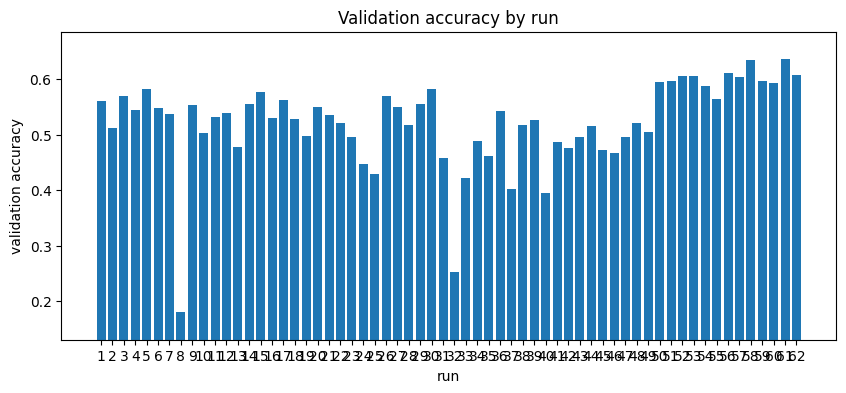

In [ ]:
log_df = pd.DataFrame(experiment_log)
shown = [c for c in ["run", "notes", "learning_rate", "batch_size", "optimizer", "dropout", "l2",
                     "base_filters", "num_blocks", "dense_units", "augment", "use_lr_schedule",
                     "train_acc", "val_acc", "gap", "best_epoch", "minutes"] if c in log_df.columns]
display(log_df[shown].sort_values("val_acc", ascending=False).reset_index(drop=True))

plt.figure(figsize=(10, 4))
plt.bar(log_df["run"].astype(str), log_df["val_acc"])
plt.xlabel("run"); plt.ylabel("validation accuracy"); plt.title("Validation accuracy by run")
plt.ylim(max(0, log_df["val_acc"].min() - 0.05), min(1, log_df["val_acc"].max() + 0.05))
plt.show()

In [ ]:
# Optional: download your log (and keep it safe, Colab deletes files when the session ends)
from google.colab import files
files.download("experiment_log.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 7: The final exam (run this ONCE)

When you are finished tuning, evaluate your best saved model on the test set. This tells you how well it will work on brand new images.

If you now go back and tune further because of this number, it stops being a fair test. So do this only when you are done.

In [ ]:
best_model = keras.models.load_model(BEST_MODEL_FILE)
test_loss, test_acc = best_model.evaluate(x_test, y_test, verbose=0)
print(f"Best validation accuracy during tuning: {best_val_so_far:.4f}")
print(f"FINAL TEST ACCURACY:                    {test_acc:.4f}")

# Which classes does the model handle best and worst?
preds = np.argmax(best_model.predict(x_test, verbose=0), axis=1)
per_class = pd.Series({CLASS_NAMES[c]: float(np.mean(preds[y_test == c] == c)) for c in range(NUM_CLASSES)}).sort_values()
print("\nHardest classes:\n", per_class.head(5).round(2).to_string())
print("\nEasiest classes:\n", per_class.tail(5).round(2).to_string())

Best validation accuracy during tuning: 0.6355
FINAL TEST ACCURACY:                    0.6318

Hardest classes:
 sweet_pepper    0.42
lobster         0.42
bowl            0.44
lizard          0.44
clock           0.47

Easiest classes:
 bridge    0.78
apple     0.79
beaver    0.80
rose      0.81
orange    0.85


## Reflection questions

Write short answers in a text cell or in your report:

1. Which single change gave the biggest improvement? Why do you think it helped?
2. Did any change make results worse? What does that teach you?
3. Look at the `gap` column. When was your model overfitting the most?
4. How different were your validation and test accuracy? What would a very large difference mean?
5. If you had two more hours, what would you try next?

1. use_lr_schedule to true was a major factor along with augment which monitored the validation loss and slashed learning rate in half if it didnt improve for 2 epochs so helping increasing accuracy if model stagnates and the latter does random image flipping so that the model learns solid patterns rather than weak unrelated patterns that can break with different dataset

2.Yes, changing l2 to higher ones like in order of 10 power -3 did hurt the result, it tells us the aggressive penalty laid on it and the model focuses on reducing weights to zero rather than classifying images correctly

3. on run 27 the model was the worst one in overfitting as the model had free path to memorize the training data due to lack of augmentation and sufficient regularization, it didnt learn the general features but just learnt the training data well

4. the validation and test accuracy were close confirming that the model was trained well to generalise the unseen data too, i.e. it had worked out the general patterns instead of overfitting to the training data, and hence could perform well in the training unseen data as well, a large difference would mean the model was a overfitting one as it learnt the patterns in the training data only and didnt perform well in the new unseen training data, signifying that it did not learn the best general patterns

5. if i had two more hours, i would try num_blocks feature by changing it to 4 along with base_filters to give network greater capacity to line fine visual patterns, the num_blocks helps increase the depth of the cnn and analyse deeper and learn more abstract general patterns